In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
df = pd.read_csv("Bank Profitability.csv")
df.head()

,Bank,Year,Period,CAR,ETA,LLP,OER,NIIR,ROA,ROE,NIM,INFL,GDP,COVIDdummy,PostCOVIDdummy
0,Bank Asia,2017,pre,14.89,7.29,1.22,44.12,1.93,0.76,9.73,2.48,5.70,6.59,0,0
1,Bank Asia,2018,pre,15.05,8.02,1.67,42.92,2.02,0.76,10.21,3.39,5.54,7.32,0,0
2,Bank Asia,2019,pre,17.93,6.95,2.48,42.00,2.17,0.59,7.97,2.37,5.59,7.88,0,0
3,Bank Asia,2020,covid,17.16,6.66,0.72,53.93,2.44,0.53,7.81,0.78,5.69,3.45,1,0
4,Bank Asia,2021,covid,15.72,6.21,1.58,44.93,2.52,0.64,9.89,1.29,5.55,6.94,1,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63 entries, 0 to 62
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Bank            63 non-null     object 
 1   Year            63 non-null     int64  
 2   Period          63 non-null     object 
 3   CAR             63 non-null     float64
 4   ETA             63 non-null     float64
 5   LLP             63 non-null     float64
 6   OER             63 non-null     float64
 7   NIIR            63 non-null     float64
 8   ROA             63 non-null     float64
 9   ROE             63 non-null     float64
 10  NIM             63 non-null     float64
 11  INFL            63 non-null     float64
 12  GDP             63 non-null     float64
 13  COVIDdummy      63 non-null     int64  
 14  PostCOVIDdummy  63 non-null     int64  
dtypes: float64(10), int64(3), object(2)
memory usage: 7.5+ KB


In [4]:
df.describe()

,Year,CAR,ETA,LLP,OER,NIIR,ROA,ROE,NIM,INFL,GDP,COVIDdummy,PostCOVIDdummy
count,63.000000,63.000000,63.000000,63.000000,63.000000,63.000000,63.000000,63.000000,63.000000,63.000000,63.000000,63.000000,63.000000
mean,2020.000000,14.625079,7.579206,1.682381,52.079524,38.504603,1.813810,11.218095,2.826508,6.521429,6.437143,0.285714,0.285714
std,2.016065,1.776569,1.328133,1.114818,9.988248,16.010981,2.881075,5.448696,1.193530,1.562078,1.370105,0.455383,0.455383
min,2017.000000,10.370000,4.520000,0.190000,31.930000,1.930000,0.370000,0.380000,0.490000,5.540000,3.450000,0.000000,0.000000
25%,2018.000000,13.135000,6.660000,0.855000,44.650000,31.430000,0.700000,8.590000,2.285000,5.550000,5.780000,0.000000,0.000000
50%,2020.000000,14.740000,7.580000,1.320000,50.780000,43.710000,0.920000,11.120000,2.770000,5.690000,6.940000,0.000000,0.000000
75%,2022.000000,15.660000,8.100000,2.480000,56.285000,48.105000,1.200000,14.600000,3.495000,7.700000,7.320000,1.000000,1.000000
max,2023.000000,17.930000,12.000000,4.400000,85.010000,62.340000,14.330000,31.200000,6.420000,9.880000,7.880000,1.000000,1.000000


In [5]:
df.groupby("Bank")["Year"].count()

,Year
Bank,
Bank Asia,7
City Bank,7
Dutch-Bangla Bank,7
Eastern Bank,7
Mutual Trust Bank,7
NCC Bank,7
Prime Bank,7
United Commercial Bank,7
Uttara Bank,7


In [6]:
# Descriptive Statistics
desc = df[['ROA','ROE','NIM','CAR','ETA','LLP','OER','NIIR','INFL','GDP']].describe().T
desc

,count,mean,std,min,25%,50%,75%,max
ROA,63.0,1.813810,2.881075,0.37,0.700,0.92,1.200,14.33
ROE,63.0,11.218095,5.448696,0.38,8.590,11.12,14.600,31.20
NIM,63.0,2.826508,1.193530,0.49,2.285,2.77,3.495,6.42
CAR,63.0,14.625079,1.776569,10.37,13.135,14.74,15.660,17.93
ETA,63.0,7.579206,1.328133,4.52,6.660,7.58,8.100,12.00
LLP,63.0,1.682381,1.114818,0.19,0.855,1.32,2.480,4.40
OER,63.0,52.079524,9.988248,31.93,44.650,50.78,56.285,85.01
NIIR,63.0,38.504603,16.010981,1.93,31.430,43.71,48.105,62.34
INFL,63.0,6.521429,1.562078,5.54,5.550,5.69,7.700,9.88
GDP,63.0,6.437143,1.370105,3.45,5.780,6.94,7.320,7.88


In [7]:
desc.to_csv("descriptive_statistics.csv")

In [8]:
period_means = df.groupby("Period")[['ROA','ROE','NIM']].mean()
period_means

,ROA,ROE,NIM
Period,,,
covid,1.761111,11.221667,2.555556
post,2.312222,11.935000,2.624444
pre,1.516667,10.737778,3.141852


In [9]:
corr_mat = df[['ROA','ROE','NIM','CAR','ETA','LLP','OER','NIIR']].corr()
corr_mat

,ROA,ROE,NIM,CAR,ETA,LLP,OER,NIIR
ROA,1.000000,-0.573695,0.091759,0.452689,0.693454,-0.258203,-0.110956,0.197740
ROE,-0.573695,1.000000,0.472546,-0.127794,-0.324848,-0.043069,0.004188,-0.013775
NIM,0.091759,0.472546,1.000000,0.096587,0.265783,-0.378767,-0.047272,0.096982
CAR,0.452689,-0.127794,0.096587,1.000000,0.266851,-0.275190,-0.046706,-0.207737
ETA,0.693454,-0.324848,0.265783,0.266851,1.000000,-0.216592,-0.282667,0.359325
LLP,-0.258203,-0.043069,-0.378767,-0.275190,-0.216592,1.000000,0.156969,0.020765
OER,-0.110956,0.004188,-0.047272,-0.046706,-0.282667,0.156969,1.000000,0.066714
NIIR,0.197740,-0.013775,0.096982,-0.207737,0.359325,0.020765,0.066714,1.000000


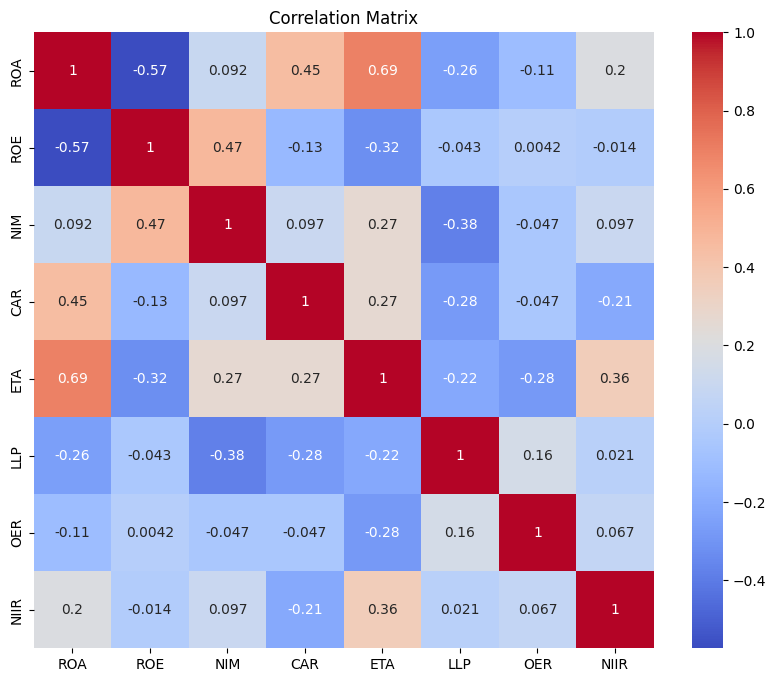

In [10]:
plt.figure(figsize=(10,8))
sns.heatmap(corr_mat,
            annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

In [11]:
# Multicolinearity test
X = df[['CAR','ETA','LLP','OER','NIIR','INFL','GDP']]
X = sm.add_constant(X)

vif = pd.DataFrame()
vif["Variable"] = X.columns
vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif

,Variable,VIF
0,const,206.472578
1,CAR,1.438683
2,ETA,1.558855
3,LLP,1.178751
4,OER,1.160443
5,NIIR,1.387897
6,INFL,1.125231
7,GDP,1.055585


In [12]:
df.columns

Index(['Bank', 'Year', 'Period', 'CAR', 'ETA', 'LLP', 'OER', 'NIIR', 'ROA',
       'ROE', 'NIM', 'INFL', 'GDP', 'COVIDdummy', 'PostCOVIDdummy'],
      dtype='object')

In [13]:
test_model = smf.ols("ROA ~ CAR + ETA + LLP + OER + NIIR + INFL + GDP + COVIDdummy + PostCOVIDdummy + C(Bank)", data=df).fit()
print(test_model.summary())

                            OLS Regression Results                            
Dep. Variable:                    ROA   R-squared:                       0.885
Model:                            OLS   Adj. R-squared:                  0.842
Method:                 Least Squares   F-statistic:                     20.42
Date:                Sun, 28 Dec 2025   Prob (F-statistic):           1.04e-15
Time:                        11:05:03   Log-Likelihood:                -87.363
No. Observations:                  63   AIC:                             210.7
Df Residuals:                      45   BIC:                             249.3
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
                                        coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Interc

In [14]:
# Model (ROA)
model_roa = smf.ols(
    "ROA ~ CAR + ETA + LLP + OER + NIIR + INFL + GDP + COVIDdummy + PostCOVIDdummy + C(Bank)",
    data=df
).fit(cov_type="HC3")

print(model_roa.summary())

                            OLS Regression Results                            
Dep. Variable:                    ROA   R-squared:                       0.885
Model:                            OLS   Adj. R-squared:                  0.842
Method:                 Least Squares   F-statistic:                     9.774
Date:                Sun, 28 Dec 2025   Prob (F-statistic):           5.00e-10
Time:                        11:05:05   Log-Likelihood:                -87.363
No. Observations:                  63   AIC:                             210.7
Df Residuals:                      45   BIC:                             249.3
Df Model:                          17                                         
Covariance Type:                  HC3                                         
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Interc

In [15]:
# Model ROE
model_roe = smf.ols(
    "ROE ~ CAR + ETA + LLP + OER + NIIR + INFL + GDP + COVIDdummy + PostCOVIDdummy + C(Bank)",
    data=df
).fit(cov_type="HC3")

print(model_roe.summary())

                            OLS Regression Results                            
Dep. Variable:                    ROE   R-squared:                       0.769
Model:                            OLS   Adj. R-squared:                  0.682
Method:                 Least Squares   F-statistic:                     16.81
Date:                Sun, 28 Dec 2025   Prob (F-statistic):           3.97e-14
Time:                        11:05:07   Log-Likelihood:                -149.54
No. Observations:                  63   AIC:                             335.1
Df Residuals:                      45   BIC:                             373.7
Df Model:                          17                                         
Covariance Type:                  HC3                                         
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Interc

In [16]:
# Model NIM
model_nim = smf.ols(
    "NIM ~ CAR + ETA + LLP + OER + NIIR + INFL + GDP + COVIDdummy + PostCOVIDdummy + C(Bank)",
    data=df
).fit(cov_type="HC3")

print(model_nim.summary())

                            OLS Regression Results                            
Dep. Variable:                    NIM   R-squared:                       0.792
Model:                            OLS   Adj. R-squared:                  0.714
Method:                 Least Squares   F-statistic:                     8.741
Date:                Sun, 28 Dec 2025   Prob (F-statistic):           2.96e-09
Time:                        11:05:09   Log-Likelihood:                -50.512
No. Observations:                  63   AIC:                             137.0
Df Residuals:                      45   BIC:                             175.6
Df Model:                          17                                         
Covariance Type:                  HC3                                         
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Interc

In [17]:
# STRUCTURAL CHANGE TEST (THIS MAKES IT STRONG)
# Digital/efficiency effect after COVID
model_interaction = smf.ols(
    "ROA ~ CAR + ETA + LLP + OER*PostCOVIDdummy + NIIR*PostCOVIDdummy + INFL + GDP + C(Bank)",
    data=df
).fit(cov_type="HC3")

print(model_interaction.summary())

                            OLS Regression Results                            
Dep. Variable:                    ROA   R-squared:                       0.894
Model:                            OLS   Adj. R-squared:                  0.851
Method:                 Least Squares   F-statistic:                     9.162
Date:                Sun, 28 Dec 2025   Prob (F-statistic):           1.27e-09
Time:                        11:05:11   Log-Likelihood:                -84.717
No. Observations:                  63   AIC:                             207.4
Df Residuals:                      44   BIC:                             248.2
Df Model:                          18                                         
Covariance Type:                  HC3                                         
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Interc

In [18]:
# ROBUSTNESS CHECK (OPTIONAL BUT IMPRESSIVE)
# Drop COVID years, compare coefficients
df_pre = df[df['Year'] <= 2019]
df_post = df[df['Year'] >= 2022]

pre_model = smf.ols(
    "ROA ~ CAR + ETA + LLP + OER + NIIR + INFL + GDP + C(Bank)",
    data=df_pre
).fit()

post_model = smf.ols(
    "ROA ~ CAR + ETA + LLP + OER + NIIR + INFL + GDP + C(Bank)",
    data=df_post
).fit()

print(pre_model.summary())
print(post_model.summary())

                            OLS Regression Results                            
Dep. Variable:                    ROA   R-squared:                       0.975
Model:                            OLS   Adj. R-squared:                  0.941
Method:                 Least Squares   F-statistic:                     28.43
Date:                Sun, 28 Dec 2025   Prob (F-statistic):           1.23e-06
Time:                        11:05:12   Log-Likelihood:                -7.0122
No. Observations:                  27   AIC:                             46.02
Df Residuals:                      11   BIC:                             66.76
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
                                        coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Interc

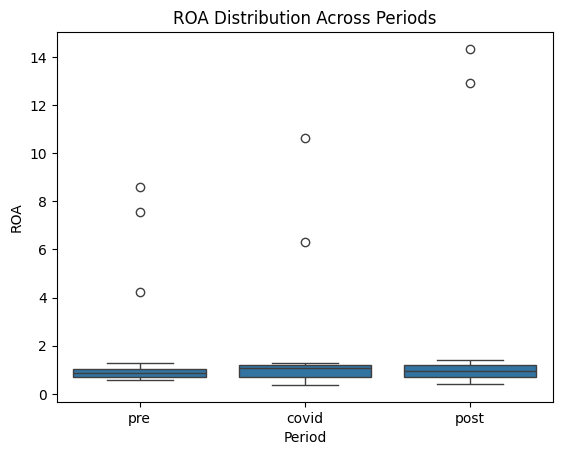

In [19]:
# Profitability distribution by period
plt.figure()
sns.boxplot(data=df, x="Period", y="ROA")
plt.title("ROA Distribution Across Periods")
plt.show()

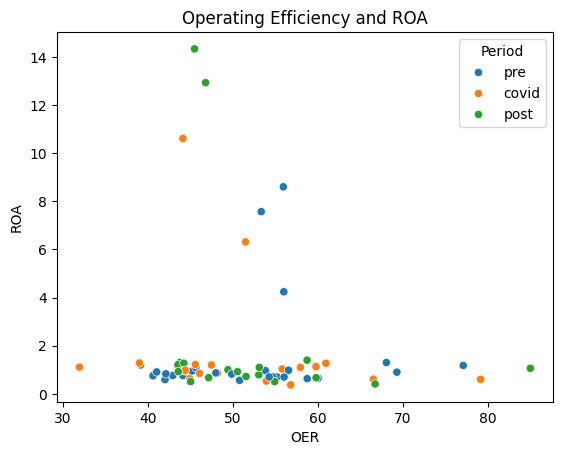

In [20]:
# Efficiency vs profitability
plt.figure()
sns.scatterplot(data=df, x="OER", y="ROA", hue="Period")
plt.title("Operating Efficiency and ROA")
plt.show()

/tmp/ipython-input-3211938099.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.lineplot(data=df, x="Year", y="ROA", estimator="mean", ci=None)


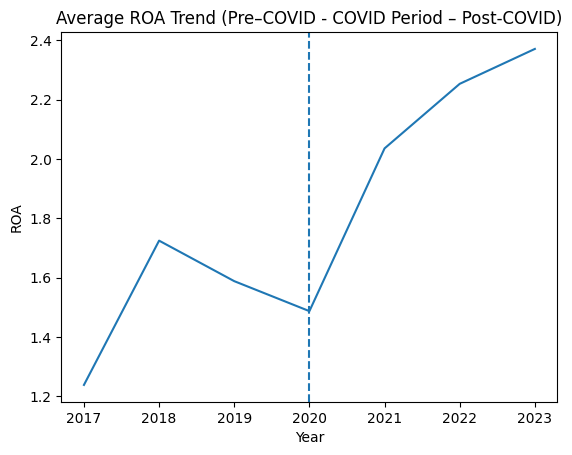

In [21]:
plt.figure()
sns.lineplot(data=df, x="Year", y="ROA", estimator="mean", ci=None)
plt.axvline(2020, linestyle="--")
plt.title("Average ROA Trend (Pre–COVID - COVID Period – Post-COVID)")
plt.show()

In [22]:
# Average profitability across periods (V-shape)
profit_period = (
    df.groupby("Period")[["ROA","ROE","NIM"]]
      .mean()
      .reset_index()
)

profit_period

,Period,ROA,ROE,NIM
0,covid,1.761111,11.221667,2.555556
1,post,2.312222,11.935000,2.624444
2,pre,1.516667,10.737778,3.141852


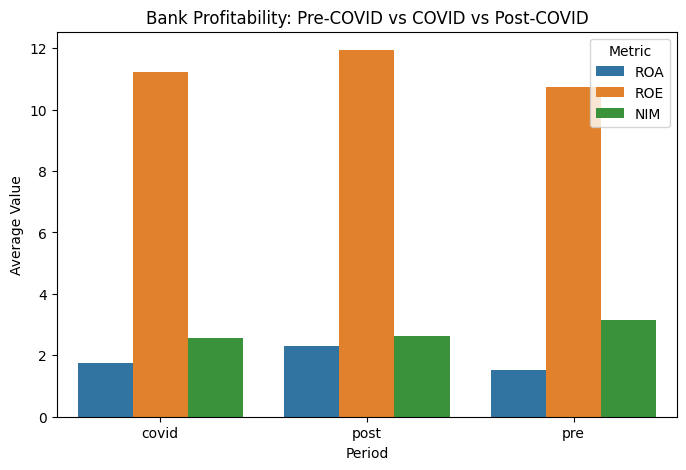

In [23]:
# Bar chart (poster-ready)
profit_period_melt = profit_period.melt(
    id_vars="Period",
    value_vars=["ROA","ROE","NIM"],
    var_name="Metric",
    value_name="Value"
)

plt.figure(figsize=(8,5))
sns.barplot(
    data=profit_period_melt,
    x="Period", y="Value", hue="Metric"
)
plt.title("Bank Profitability: Pre-COVID vs COVID vs Post-COVID")
plt.ylabel("Average Value")
plt.show()

/tmp/ipython-input-3205054106.py:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.lineplot(


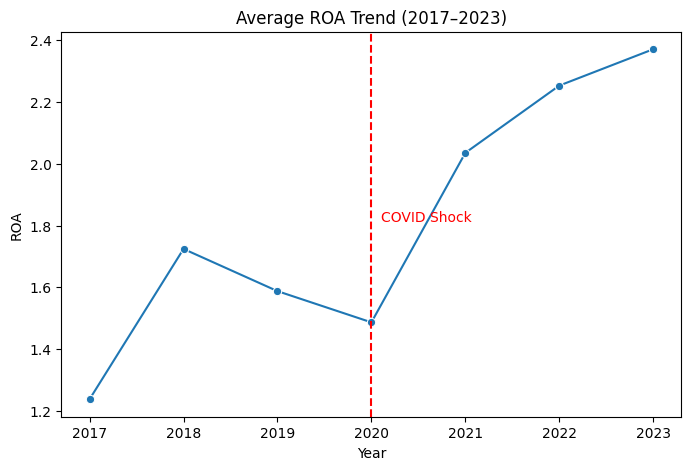

In [24]:
# Time trend (ROA)
plt.figure(figsize=(8,5))
sns.lineplot(
    data=df,
    x="Year", y="ROA",
    estimator="mean", ci=None, marker="o"
)
plt.axvline(2020, linestyle="--", color="red")
plt.text(2020.1, df['ROA'].mean(), "COVID Shock", color="red")
plt.title("Average ROA Trend (2017–2023)")
plt.ylabel("ROA")
plt.savefig('v.png', dpi=300)
plt.show()

/tmp/ipython-input-479649972.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(


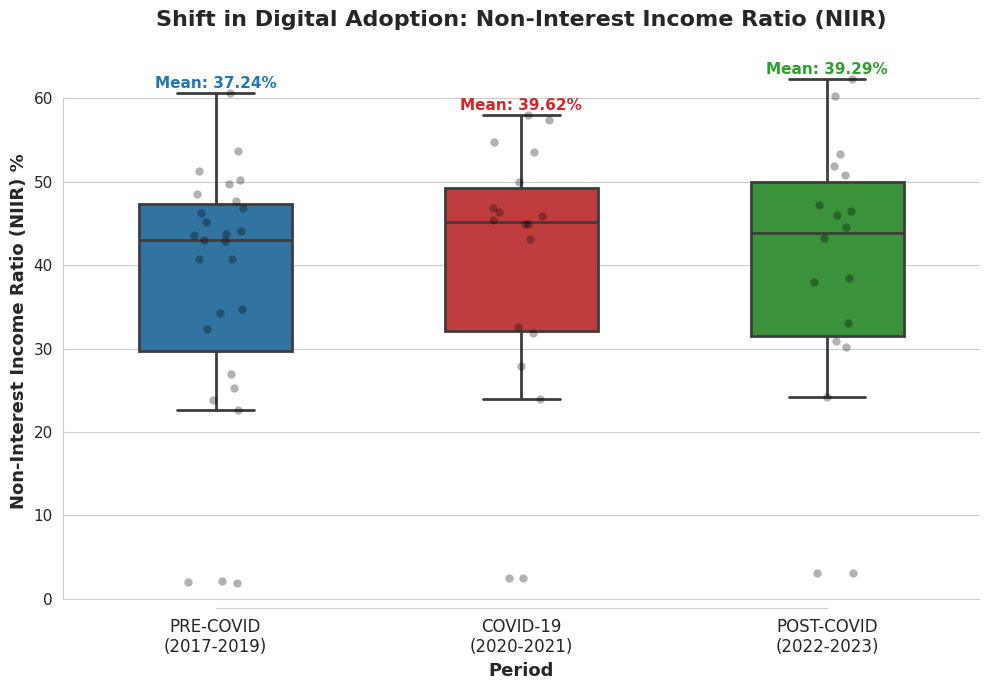

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load Data
df = pd.read_csv("Bank Profitability.csv")

# Set Style
sns.set_style("whitegrid")

# Define Period Order and Colors
period_order = ['pre', 'covid', 'post']
palette_colors = {'pre': '#1f77b4', 'covid': '#d62728', 'post': '#2ca02c'}

# Setup Plot
plt.figure(figsize=(10, 7))

# 1. Create Boxplot
ax = sns.boxplot(
    data=df,
    x="Period",
    y="NIIR",
    order=period_order,
    palette=palette_colors,
    width=0.5,
    linewidth=2,
    showfliers=False # Hide outliers in boxplot to avoid duplication with stripplot
)

# 2. Add Stripplot (Dots) for "Fancy" Scientific Look
sns.stripplot(
    data=df,
    x="Period",
    y="NIIR",
    order=period_order,
    color='black',
    alpha=0.3,
    size=6,
    jitter=True
)

# Formatting
plt.title("Shift in Digital Adoption: Non-Interest Income Ratio (NIIR)", fontsize=16, fontweight='bold', pad=20)
plt.xlabel("Period", fontsize=13, fontweight='bold')
plt.ylabel("Non-Interest Income Ratio (NIIR) %", fontsize=13, fontweight='bold')

# Customize Ticks
plt.xticks(ticks=[0, 1, 2], labels=['PRE-COVID\n(2017-2019)', 'COVID-19\n(2020-2021)', 'POST-COVID\n(2022-2023)'], fontsize=12)
plt.yticks(fontsize=11)

# Remove top and right spines
sns.despine(trim=True)

# 3. Add Mean Labels
means = df.groupby('Period')['NIIR'].mean()
for i, period in enumerate(period_order):
    mean_val = means[period]
    # Place text above the highest point in that category
    max_val = df[df['Period']==period]['NIIR'].max()
    plt.text(i, max_val + 0.2, f'Mean: {mean_val:.2f}%',
             ha='center', va='bottom', fontweight='bold', color=palette_colors[period], fontsize=11)

plt.tight_layout()
plt.savefig('niir_boxplot_fancy.png', dpi=300)
plt.show()

In [26]:
# BANK-LEVEL RESILIENCE COMPARISON
# ROA shock & recovery by bank
resilience = (
    df.pivot_table(index="Bank", columns="Period", values="ROA", aggfunc="mean")
)

resilience["Shock_Loss"] = resilience["covid"] - resilience["pre"]
resilience["Recovery_Gain"] = resilience["post"] - resilience["covid"]

resilience.sort_values("Recovery_Gain", ascending=False)

Period,covid,post,pre,Shock_Loss,Recovery_Gain
Bank,,,,,
Prime Bank,8.460,13.630,6.803333,1.656667,5.170
Mutual Trust Bank,0.700,0.755,0.780000,-0.080000,0.055
Uttara Bank,0.980,1.010,0.920000,0.060000,0.030
Dutch-Bangla Bank,1.200,1.230,1.126667,0.073333,0.030
Bank Asia,0.585,0.590,0.703333,-0.118333,0.005
Eastern Bank,1.250,1.240,1.113333,0.136667,-0.010
City Bank,1.150,1.100,0.700000,0.450000,-0.050
United Commercial Bank,0.605,0.540,0.660000,-0.055000,-0.065
NCC Bank,0.920,0.715,0.843333,0.076667,-0.205


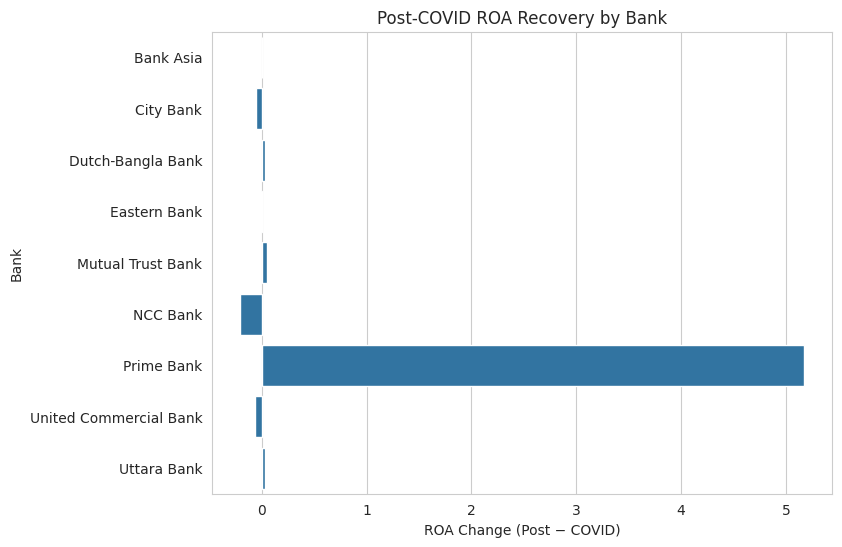

In [27]:
plt.figure(figsize=(8,6))
sns.barplot(
    x=resilience["Recovery_Gain"],
    y=resilience.index
)
plt.title("Post-COVID ROA Recovery by Bank")
plt.xlabel("ROA Change (Post − COVID)")
plt.ylabel("Bank")
plt.show()

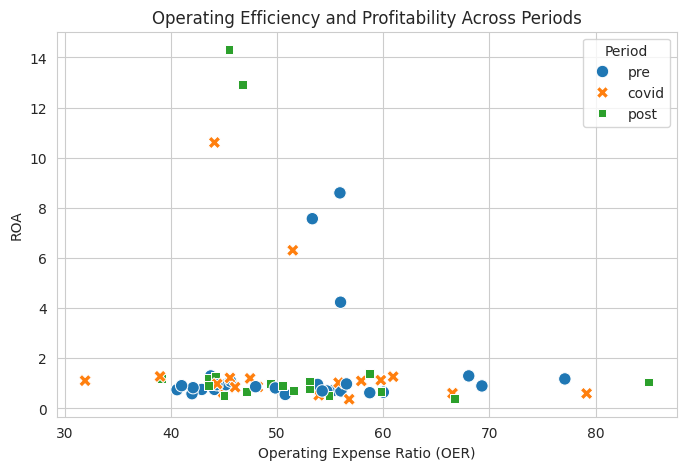

In [28]:
# DRIVER SHIFT (EFFICIENCY & DIGITAL PROXY)
# Operating efficiency vs profitability
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=df,
    x="OER", y="ROA",
    hue="Period", style="Period",
    s=80
)
plt.title("Operating Efficiency and Profitability Across Periods")
plt.xlabel("Operating Expense Ratio (OER)")
plt.ylabel("ROA")
plt.show()

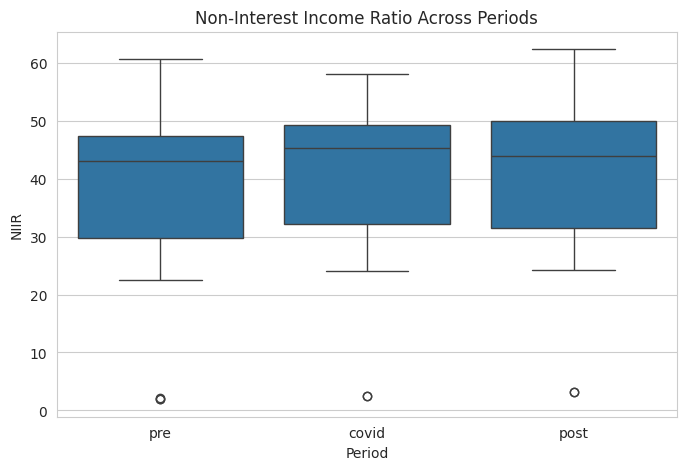

In [29]:
# Non-interest income (digital proxy)
plt.figure(figsize=(8,5))
sns.boxplot(
    data=df,
    x="Period", y="NIIR"
)
plt.title("Non-Interest Income Ratio Across Periods")
plt.ylabel("NIIR")
plt.show()

In [30]:
# LIGHT REGRESSION (ONE FIGURE ONLY)
# Fixed-effects ROA model (for coefficients)
df['Bank'] = df['Bank'].astype('category')

model_roa = smf.ols(
    """
    ROA ~ CAR + ETA + LLP + OER + NIIR + INFL + GDP
          + COVIDdummy + PostCOVIDdummy
          + C(Bank)
    """,
    data=df
).fit(cov_type="HC3")

model_roa.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    ROA   R-squared:                       0.885
Model:                            OLS   Adj. R-squared:                  0.842
Method:                 Least Squares   F-statistic:                     9.774
Date:                Sun, 28 Dec 2025   Prob (F-statistic):           5.00e-10
Time:                        11:05:40   Log-Likelihood:                -87.363
No. Observations:                  63   AIC:                             210.7
Df Residuals:                      45   BIC:                             249.3
Df Model:                          17                                         
Covariance Type:                  HC3                                         
=====================================================================================================
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Intercept                            -2.5169      4.151     -0.606      0.544     -10.653       5.619
C(Bank)[T.City Bank]                  1.7061      1.797      0.950      0.342      -1.816       5.228
C(Bank)[T.Dutch-Bangla Bank]          2.2476      1.503      1.496      0.135      -0.698       5.193
C(Bank)[T.Eastern Bank]               1.8288      1.840      0.994      0.320      -1.777       5.435
C(Bank)[T.Mutual Trust Bank]          1.6576      1.516      1.094      0.274      -1.313       4.628
C(Bank)[T.NCC Bank]                   1.5157      1.851      0.819      0.413      -2.112       5.144
C(Bank)[T.Prime Bank]                 9.0679      1.760      5.153      0.000       5.619      12.517
C(Bank)[T.United Commercial Bank]     2.1639      2.185      0.990      0.322      -2.119       6.447
C(Bank)[T.Uttara Bank]                1.3583      1.579      0.860      0.390      -1.736       4.453
CAR                                   0.0823      0.192      0.428      0.669      -0.295       0.459
ETA                                   0.3188      0.329      0.968      0.333      -0.327       0.964
LLP                                  -0.0336      0.157     -0.213      0.831      -0.342       0.275
OER                                  -0.0320      0.028     -1.152      0.249      -0.086       0.022
NIIR                                 -0.0311      0.033     -0.937      0.349      -0.096       0.034
INFL                                  0.0173      0.445      0.039      0.969      -0.854       0.889
GDP                                   0.1233      0.127      0.969      0.332      -0.126       0.373
COVIDdummy                            0.3655      0.322      1.135      0.256      -0.266       0.997
PostCOVIDdummy                        0.7939      1.326      0.599      0.549      -1.805       3.393
==============================================================================
Omnibus:                       26.899   Durbin-Watson:                   1.504
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              205.502
Skew:                           0.688   Prob(JB):                     2.38e-45
Kurtosis:                      11.740   Cond. No.                     1.83e+03
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
[2] The condition number is large, 1.83e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

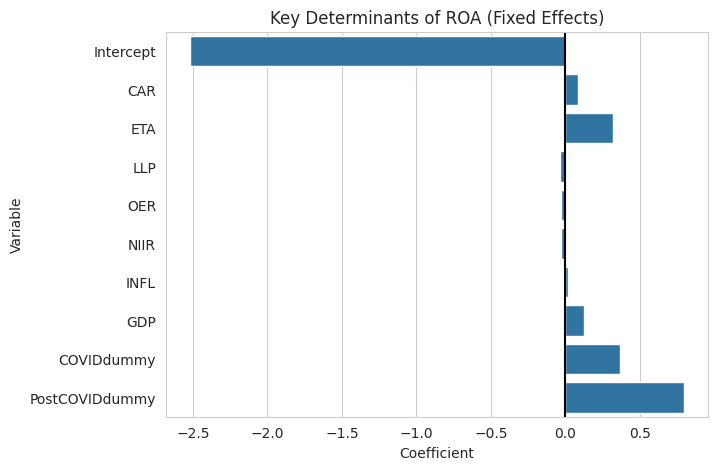

In [31]:
# Coefficient visualization (poster-safe)
coef_df = (
    model_roa.params
    .reset_index()
    .rename(columns={'index':'Variable', 0:'Coefficient'})
)

coef_df = coef_df[~coef_df["Variable"].str.contains("C\\(Bank\\)")]

plt.figure(figsize=(7,5))
sns.barplot(
    data=coef_df,
    x="Coefficient", y="Variable"
)
plt.axvline(0, color="black")
plt.title("Key Determinants of ROA (Fixed Effects)")
plt.show()

/tmp/ipython-input-2716271672.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bank_roa = df.groupby("Bank")["ROA"].mean().sort_values()


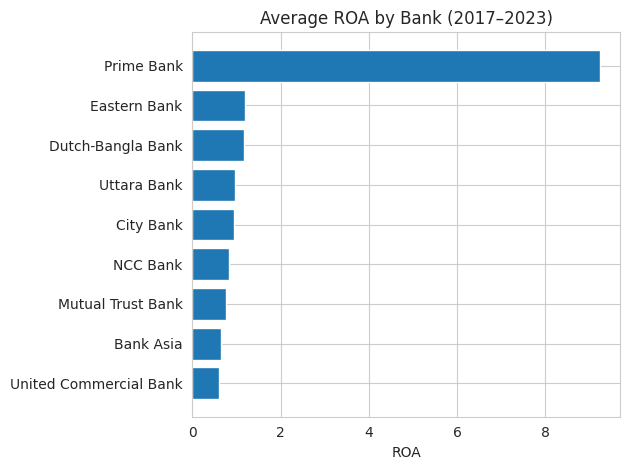

In [32]:
bank_roa = df.groupby("Bank")["ROA"].mean().sort_values()

plt.figure()
plt.barh(bank_roa.index, bank_roa.values)
plt.title("Average ROA by Bank (2017–2023)")
plt.xlabel("ROA")
plt.tight_layout()
plt.show()

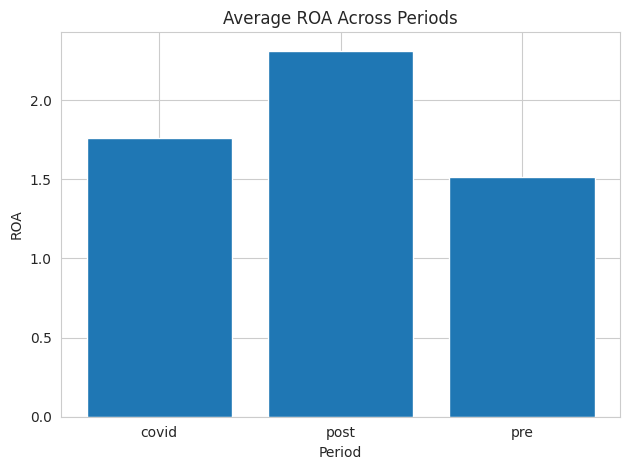

In [33]:
period_roa = df.groupby("Period")["ROA"].mean()

plt.figure()
plt.bar(period_roa.index, period_roa.values)
plt.title("Average ROA Across Periods")
plt.xlabel("Period")
plt.ylabel("ROA")
plt.tight_layout()
plt.show()

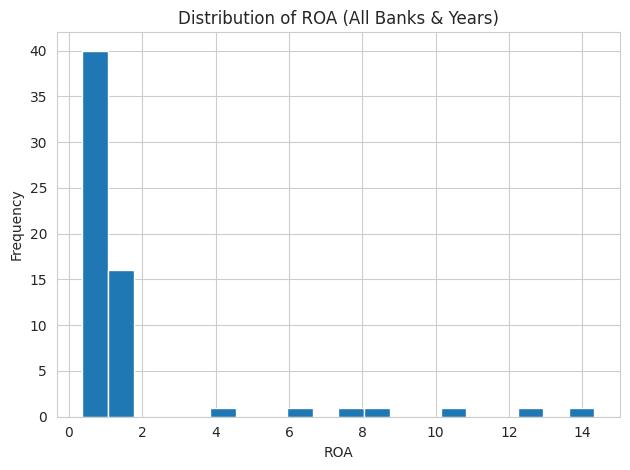

In [34]:
plt.figure()
plt.hist(df["ROA"].dropna(), bins=20)
plt.title("Distribution of ROA (All Banks & Years)")
plt.xlabel("ROA")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

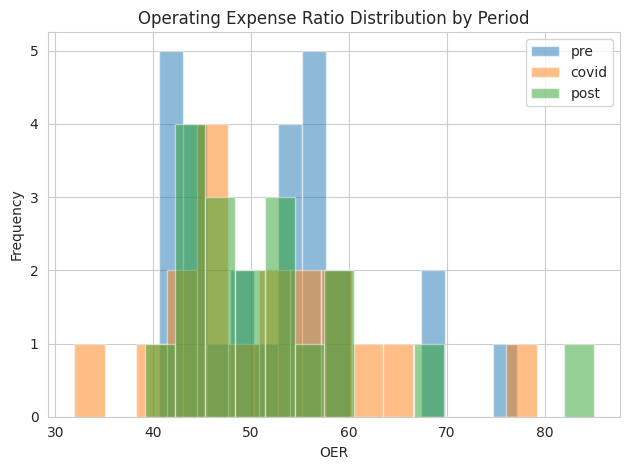

In [35]:
plt.figure()
for p in df["Period"].unique():
    subset = df[df["Period"] == p]["OER"].dropna()
    plt.hist(subset, bins=15, alpha=0.5, label=p)

plt.legend()
plt.title("Operating Expense Ratio Distribution by Period")
plt.xlabel("OER")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

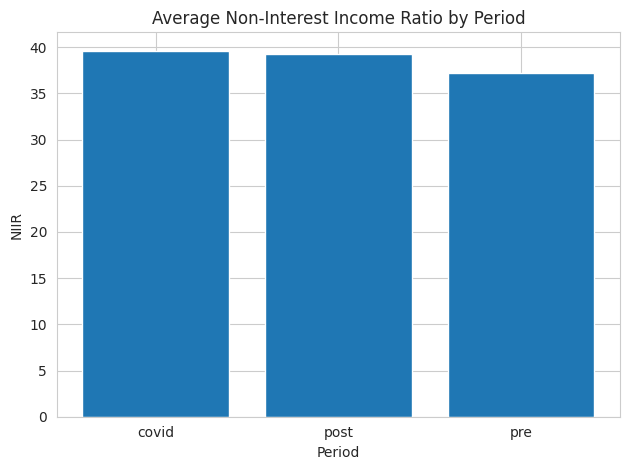

In [36]:
niir_period = df.groupby("Period")["NIIR"].mean()

plt.figure()
plt.bar(niir_period.index, niir_period.values)
plt.title("Average Non-Interest Income Ratio by Period")
plt.xlabel("Period")
plt.ylabel("NIIR")
plt.tight_layout()
plt.show()

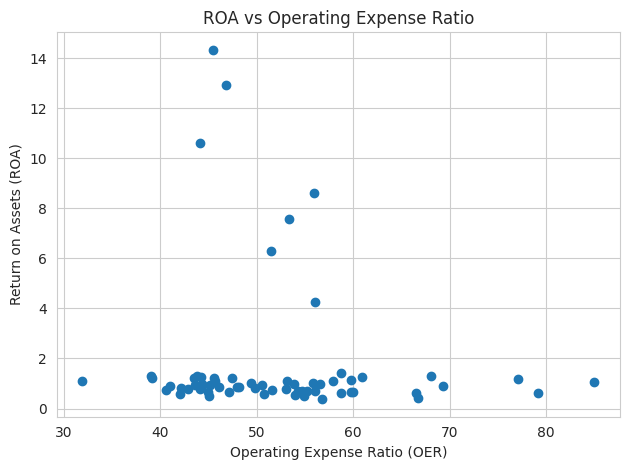

In [37]:
plt.figure()
plt.scatter(df["OER"], df["ROA"])
plt.xlabel("Operating Expense Ratio (OER)")
plt.ylabel("Return on Assets (ROA)")
plt.title("ROA vs Operating Expense Ratio")
plt.tight_layout()
plt.show()

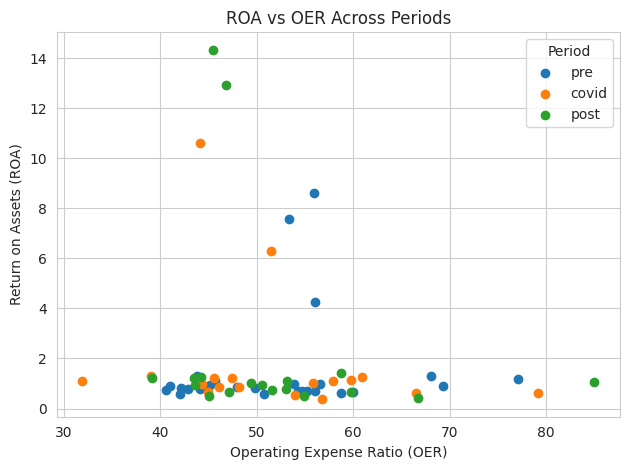

In [38]:
plt.figure()

for p in df["Period"].unique():
    sub = df[df["Period"] == p]
    plt.scatter(sub["OER"], sub["ROA"], label=p)

plt.xlabel("Operating Expense Ratio (OER)")
plt.ylabel("Return on Assets (ROA)")
plt.title("ROA vs OER Across Periods")
plt.legend(title="Period")
plt.tight_layout()
plt.savefig('scatter.png', dpi=300)
plt.show()

/tmp/ipython-input-2542616652.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bank_avg = df.groupby("Bank")[["OER","ROA"]].mean()


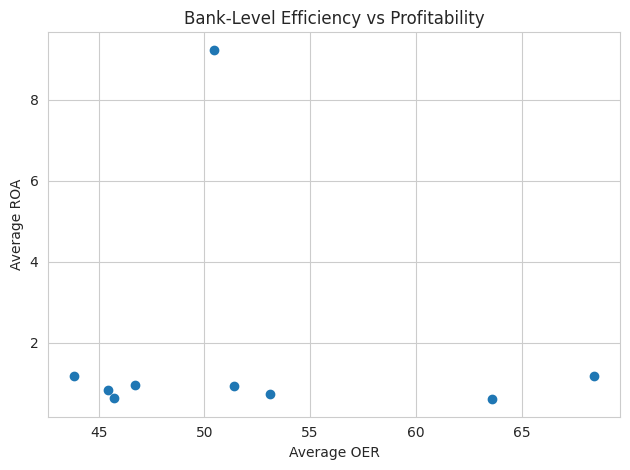

In [39]:
bank_avg = df.groupby("Bank")[["OER","ROA"]].mean()

plt.figure()
plt.scatter(bank_avg["OER"], bank_avg["ROA"])
plt.xlabel("Average OER")
plt.ylabel("Average ROA")
plt.title("Bank-Level Efficiency vs Profitability")
plt.tight_layout()
plt.show()

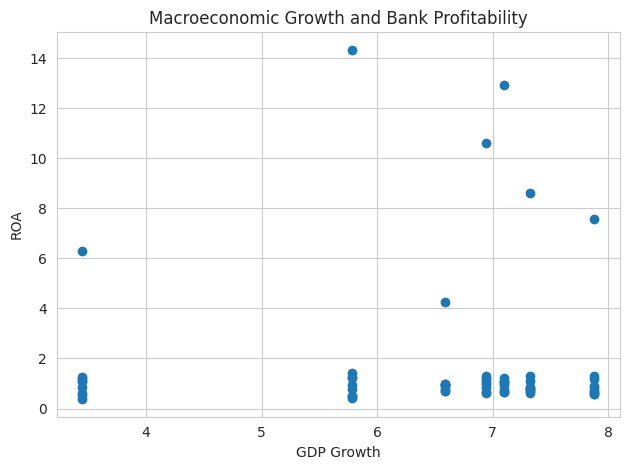

In [40]:
plt.figure()
plt.scatter(df["GDP"], df["ROA"])
plt.xlabel("GDP Growth")
plt.ylabel("ROA")
plt.title("Macroeconomic Growth and Bank Profitability")
plt.tight_layout()
plt.show()

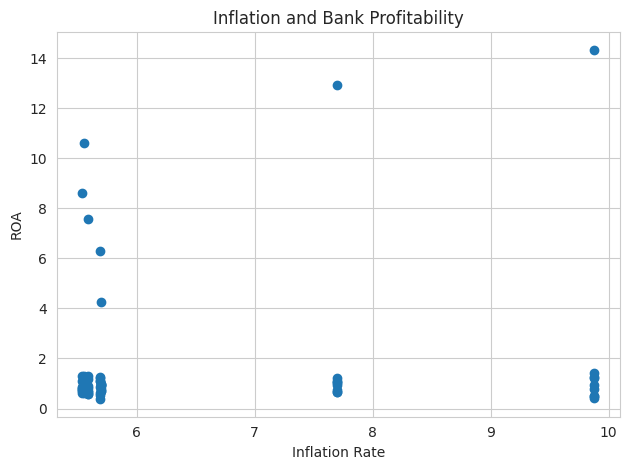

In [41]:
plt.figure()
plt.scatter(df["INFL"], df["ROA"])
plt.xlabel("Inflation Rate")
plt.ylabel("ROA")
plt.title("Inflation and Bank Profitability")
plt.tight_layout()
plt.show()

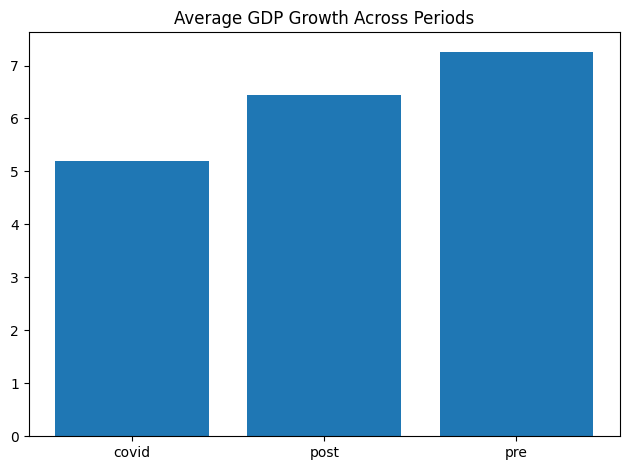

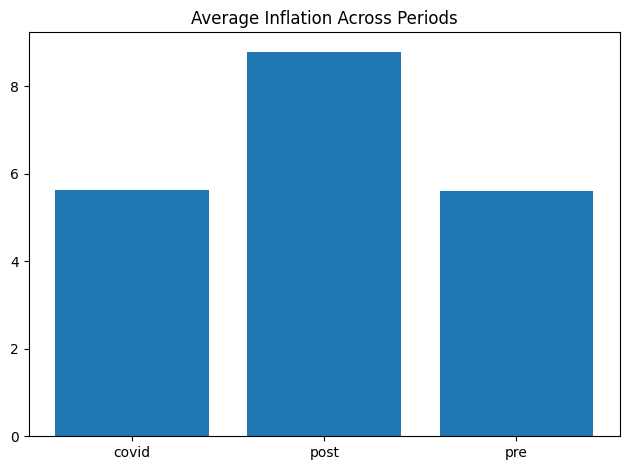

In [ ]:
macro = df.groupby("Period")[["GDP","INFL"]].mean()

plt.figure()
plt.bar(macro.index, macro["GDP"])
plt.title("Average GDP Growth Across Periods")
plt.tight_layout()
plt.show()

plt.figure()
plt.bar(macro.index, macro["INFL"])
plt.title("Average Inflation Across Periods")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import numpy as np
# Interaction terms
df["OER_GDP"] = df["OER"] * df["GDP"]
df["OER_INFL"] = df["OER"] * df["INFL"]

In [ ]:
model_interaction = smf.ols(
    "ROA ~ OER + GDP + INFL + OER_GDP + OER_INFL + CAR + ETA + LLP + NIIR + COVIDdummy + PostCOVIDdummy + C(Bank)",
    data=df
).fit(cov_type="HC3")

print(model_interaction.summary())

                            OLS Regression Results                            
Dep. Variable:                    ROA   R-squared:                       0.891
Model:                            OLS   Adj. R-squared:                  0.842
Method:                 Least Squares   F-statistic:                     9.793
Date:                Sat, 27 Dec 2025   Prob (F-statistic):           4.19e-10
Time:                        16:04:32   Log-Likelihood:                -85.863
No. Observations:                  63   AIC:                             211.7
Df Residuals:                      43   BIC:                             254.6
Df Model:                          19                                         
Covariance Type:                  HC3                                         
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Interc

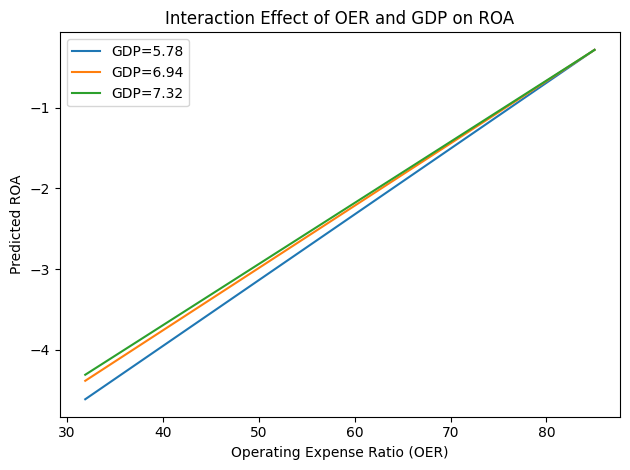

In [ ]:
# Low, Mean, High GDP
gdp_levels = np.percentile(df["GDP"], [25, 50, 75])
oer_range = np.linspace(df["OER"].min(), df["OER"].max(), 50)

plt.figure()

for gdp in gdp_levels:
    roa_pred = (
        model_interaction.params["Intercept"]
        + model_interaction.params["OER"] * oer_range
        + model_interaction.params["GDP"] * gdp
        + model_interaction.params["OER_GDP"] * oer_range * gdp
    )
    plt.plot(oer_range, roa_pred, label=f"GDP={round(gdp,2)}")

plt.xlabel("Operating Expense Ratio (OER)")
plt.ylabel("Predicted ROA")
plt.title("Interaction Effect of OER and GDP on ROA")
plt.legend()
plt.tight_layout()
plt.show()

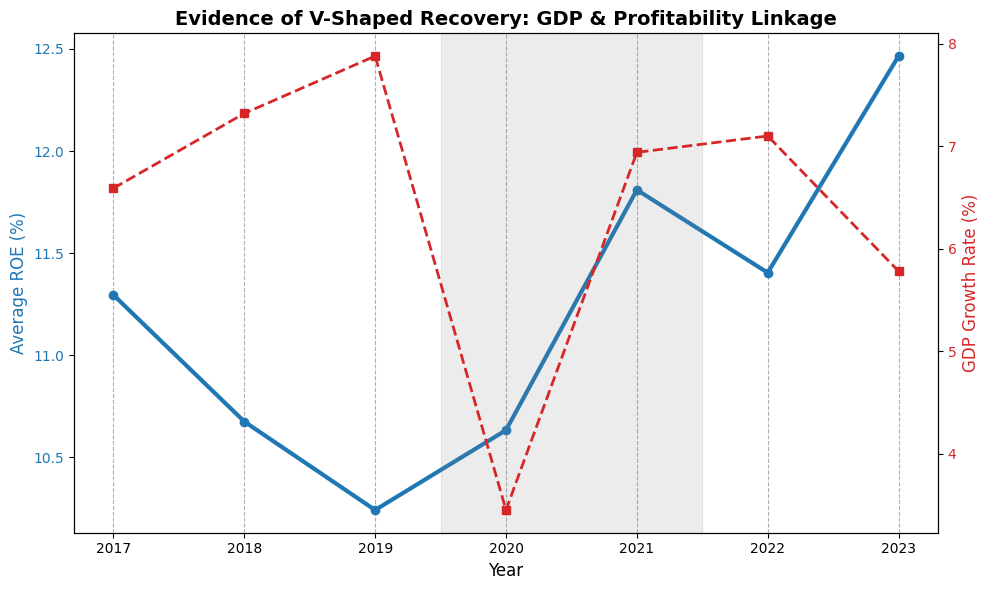

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
df = pd.read_csv("Bank Profitability.csv")

# Group by Year to get industry averages
annual_avg = df.groupby('Year')[['ROA', 'ROE', 'GDP']].mean().reset_index()

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot ROE (Primary Axis)
color_roe = 'tab:blue'
ax1.set_xlabel('Year', fontsize=12)
ax1.set_ylabel('Average ROE (%)', color=color_roe, fontsize=12)
ax1.plot(annual_avg['Year'], annual_avg['ROE'], color=color_roe, marker='o', linewidth=3, label='Bank ROE')
ax1.tick_params(axis='y', labelcolor=color_roe)
ax1.grid(visible=True, which='major', axis='x', linestyle='--')

# Create a second y-axis for GDP (Mediating Variable)
ax2 = ax1.twinx()
color_gdp = 'tab:red'
ax2.set_ylabel('GDP Growth Rate (%)', color=color_gdp, fontsize=12)
ax2.plot(annual_avg['Year'], annual_avg['GDP'], color=color_gdp, linestyle='--', marker='s', linewidth=2, label='GDP Growth')
ax2.tick_params(axis='y', labelcolor=color_gdp)

# Highlight COVID Period
plt.axvspan(2019.5, 2021.5, color='gray', alpha=0.15, label='COVID-19 Shock')

plt.title('Evidence of V-Shaped Recovery: GDP & Profitability Linkage', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('v_shaped_recovery.png', dpi=300)
plt.show()

<Figure size 1000x600 with 0 Axes>

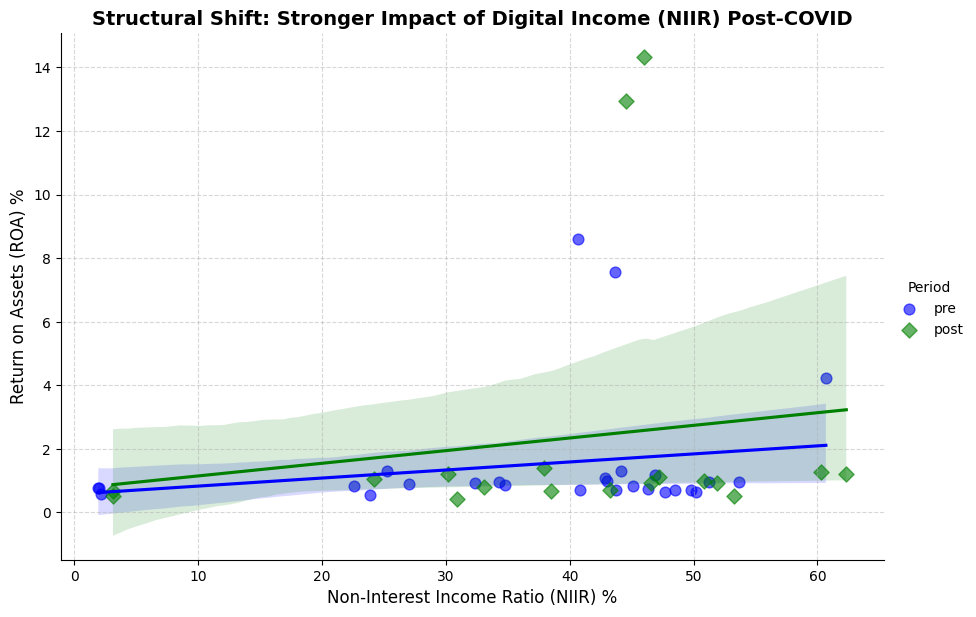

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Scatter plot with regression lines by Period
sns.lmplot(data=df[df['Period'] != 'covid'], x='NIIR', y='ROA', hue='Period',
           height=6, aspect=1.5, palette={'pre': 'blue', 'post': 'green'},
           markers=['o', 'D'], scatter_kws={'s': 60, 'alpha': 0.6})

plt.title('Structural Shift: Stronger Impact of Digital Income (NIIR) Post-COVID', fontsize=14, fontweight='bold')
plt.xlabel('Non-Interest Income Ratio (NIIR) %', fontsize=12)
plt.ylabel('Return on Assets (ROA) %', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

plt.savefig('structural_shift_niir.png', dpi=300)
plt.show()

<Figure size 1000x600 with 0 Axes>

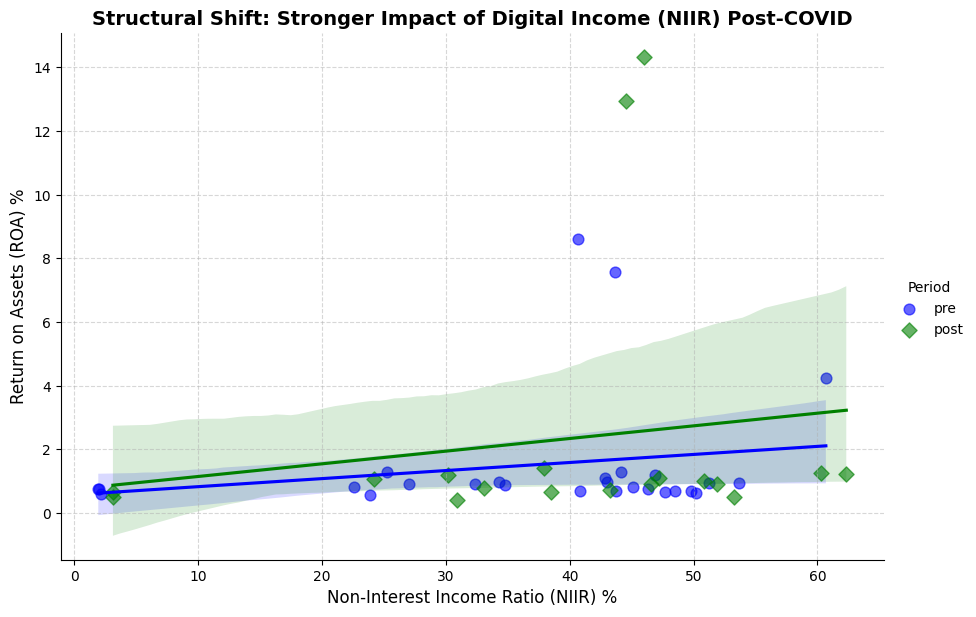

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Scatter plot with regression lines by Period
sns.lmplot(data=df[df['Period'] != 'covid'], x='NIIR', y='ROA', hue='Period',
           height=6, aspect=1.5, palette={'pre': 'blue', 'post': 'green'},
           markers=['o', 'D'], scatter_kws={'s': 60, 'alpha': 0.6})

plt.title('Structural Shift: Stronger Impact of Digital Income (NIIR) Post-COVID', fontsize=14, fontweight='bold')
plt.xlabel('Non-Interest Income Ratio (NIIR) %', fontsize=12)
plt.ylabel('Return on Assets (ROA) %', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

plt.savefig('structural_shift_niir.png', dpi=300)
plt.show()

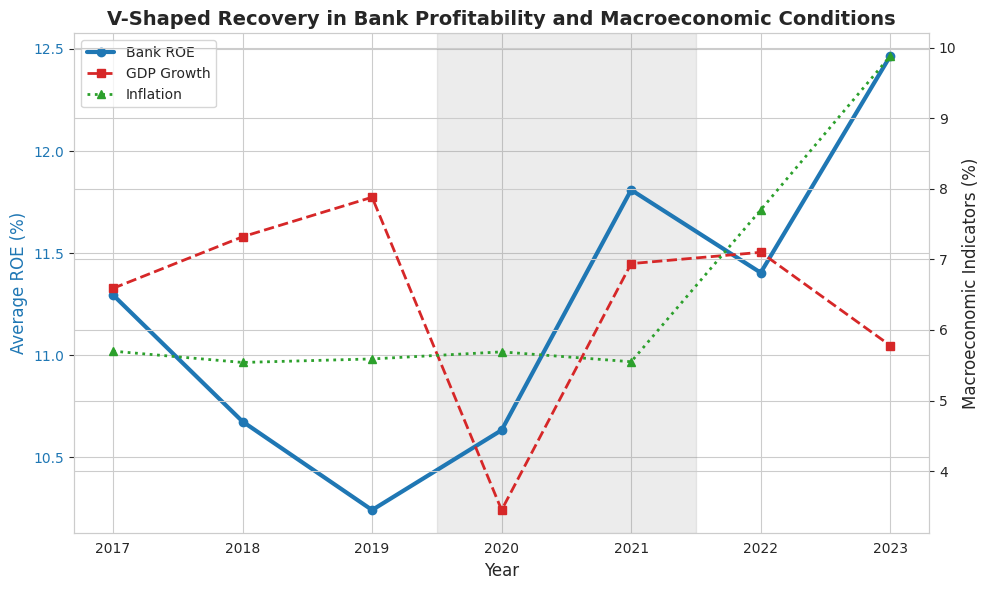

In [42]:
import pandas as pd
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv("Bank Profitability.csv")

# Group by Year
annual_avg = df.groupby('Year')[['ROE', 'GDP', 'INFL']].mean().reset_index()

fig, ax1 = plt.subplots(figsize=(10, 6))

# --- ROE (Primary Axis) ---
color_roe = 'tab:blue'
ax1.set_xlabel('Year', fontsize=12)
ax1.set_ylabel('Average ROE (%)', color=color_roe, fontsize=12)
ax1.plot(
    annual_avg['Year'],
    annual_avg['ROE'],
    color=color_roe,
    marker='o',
    linewidth=3,
    label='Bank ROE'
)
ax1.tick_params(axis='y', labelcolor=color_roe)

# --- GDP & Inflation (Secondary Axis) ---
ax2 = ax1.twinx()
color_gdp = 'tab:red'
color_infl = 'tab:green'

ax2.set_ylabel('Macroeconomic Indicators (%)', fontsize=12)
ax2.plot(
    annual_avg['Year'],
    annual_avg['GDP'],
    color=color_gdp,
    linestyle='--',
    marker='s',
    linewidth=2,
    label='GDP Growth'
)
ax2.plot(
    annual_avg['Year'],
    annual_avg['INFL'],
    color=color_infl,
    linestyle=':',
    marker='^',
    linewidth=2,
    label='Inflation'
)

# --- COVID period shading ---
ax1.axvspan(2019.5, 2021.5, color='gray', alpha=0.15)

# --- Legend (combined) ---
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left')

# --- Title ---
plt.title(
    'V-Shaped Recovery in Bank Profitability and Macroeconomic Conditions',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.savefig('v_shaped_recovery_with_inflation.png', dpi=300)
plt.show()

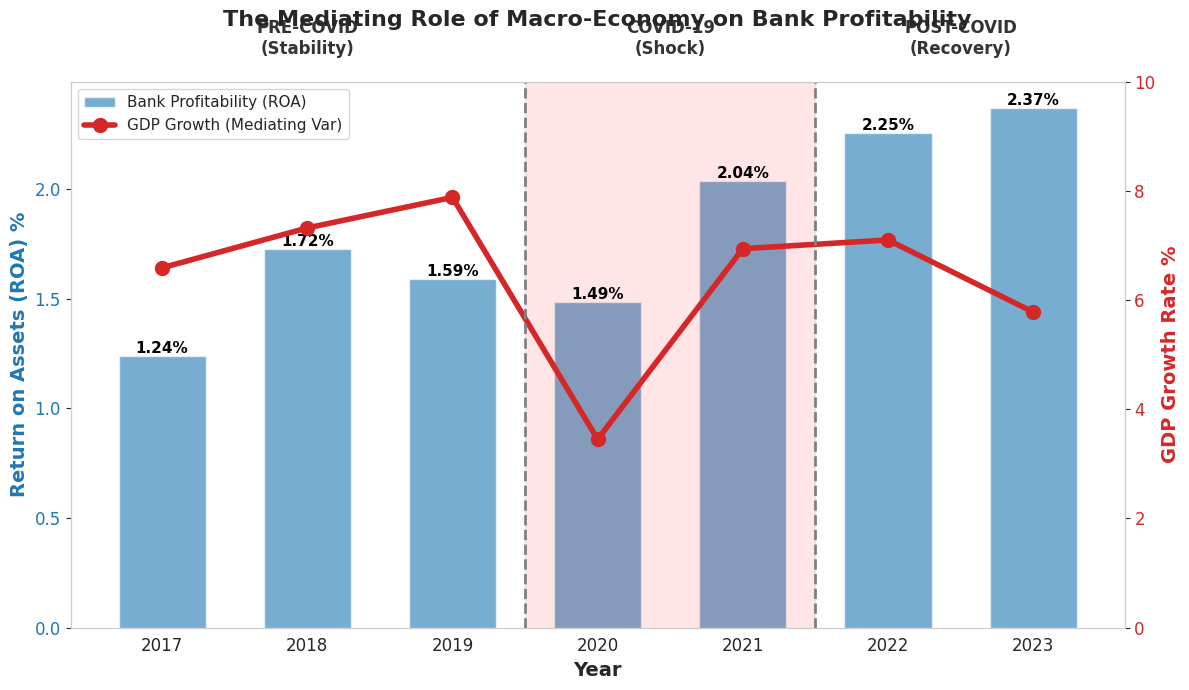

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Data
df = pd.read_csv("Bank Profitability.csv")

# 2. Group data by Year to get industry averages
yearly_data = df.groupby('Year')[['ROA', 'GDP']].mean().reset_index()

# 3. Setup the Plot
fig, ax1 = plt.subplots(figsize=(12, 7))

# --- PLOT 1: Bank Profitability (ROA) as Bars ---
# We use bars to represent the solid banking performance data
color_roa = '#1f77b4' # Professional Blue
bars = ax1.bar(yearly_data['Year'], yearly_data['ROA'], color=color_roa, alpha=0.6, label='Bank Profitability (ROA)', width=0.6)
ax1.set_xlabel('Year', fontsize=14, fontweight='bold')
ax1.set_ylabel('Return on Assets (ROA) %', color=color_roa, fontsize=14, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color_roa, labelsize=12)
ax1.tick_params(axis='x', labelsize=12)

# Add value labels on top of bars
for bar in bars:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.2f}%',
             ha='center', va='bottom', fontsize=11, fontweight='bold', color='black')

# --- PLOT 2: Macro Variable (GDP) as Line ---
# This visualizes the "Mediating Variable"
ax2 = ax1.twinx()
color_gdp = '#d62728' # Professional Red
ax2.plot(yearly_data['Year'], yearly_data['GDP'], color=color_gdp, marker='o', linestyle='-', linewidth=4, markersize=10, label='GDP Growth (Mediating Var)')
ax2.set_ylabel('GDP Growth Rate %', color=color_gdp, fontsize=14, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_gdp, labelsize=12)
ax2.set_ylim(0, 10) # Adjust scale to make lines distinct

# --- ADDING THE "PRE -> COVID -> POST" ZONES ---
# Define zone boundaries
ymax = ax1.get_ylim()[1]

# Zone 1: Pre-COVID (2017 - 2019)
plt.axvline(x=2019.5, color='gray', linestyle='--', linewidth=2)
ax1.text(2018, ymax*1.05, 'PRE-COVID\n(Stability)', ha='center', fontsize=12, fontweight='bold', color='#333')

# Zone 2: COVID (2020 - 2021)
plt.axvline(x=2021.5, color='gray', linestyle='--', linewidth=2)
ax1.text(2020.5, ymax*1.05, 'COVID-19\n(Shock)', ha='center', fontsize=12, fontweight='bold', color='#333')
# Add shaded background for COVID
ax1.axvspan(2019.5, 2021.5, color='red', alpha=0.1)

# Zone 3: Post-COVID (2022 - 2023)
ax1.text(2022.5, ymax*1.05, 'POST-COVID\n(Recovery)', ha='center', fontsize=12, fontweight='bold', color='#333')

# --- Final Formatting ---
plt.title('The Mediating Role of Macro-Economy on Bank Profitability', fontsize=16, fontweight='bold', pad=40)
ax1.grid(False)
ax2.grid(False)

# Legend (Combine both axes)
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left', fontsize=11)

plt.tight_layout()
plt.show()

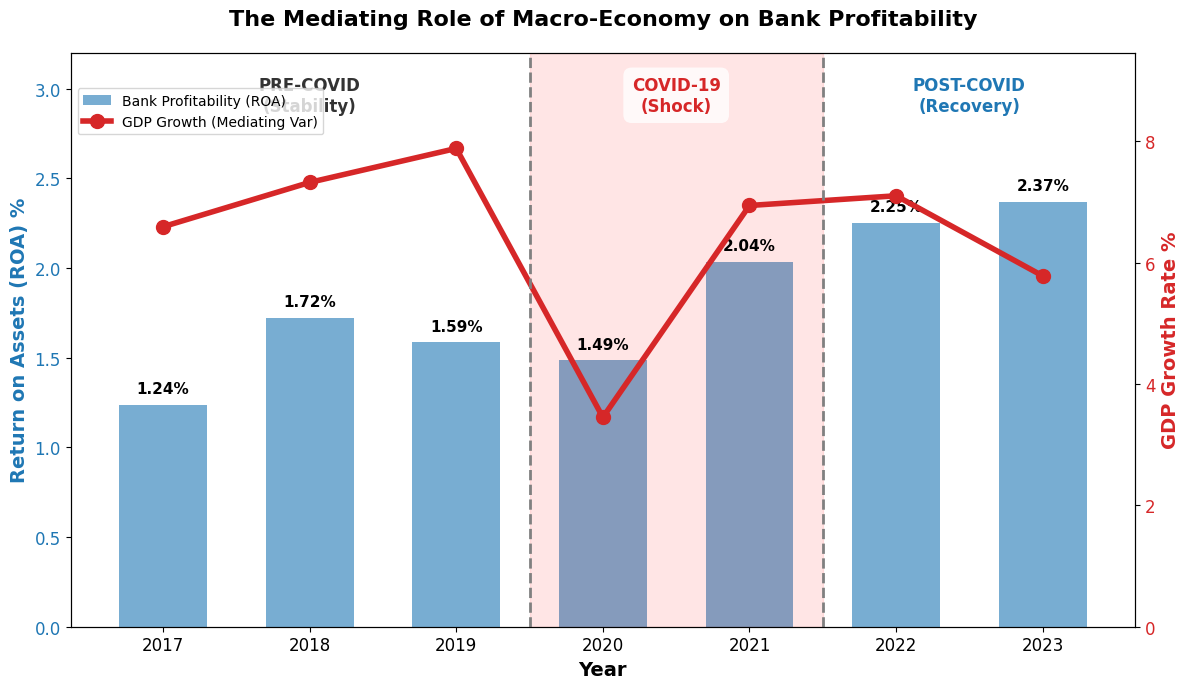

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load Data
df = pd.read_csv("Bank Profitability.csv")

# Group data by Year to get industry averages
yearly_data = df.groupby('Year')[['ROA', 'GDP']].mean().reset_index()

# Setup the Plot
fig, ax1 = plt.subplots(figsize=(12, 7))

# --- PLOT 1: Bank Profitability (ROA) as Bars ---
color_roa = '#1f77b4' # Professional Blue
bars = ax1.bar(yearly_data['Year'], yearly_data['ROA'], color=color_roa, alpha=0.6, label='Bank Profitability (ROA)', width=0.6)

# Configure Primary Axis (ROA)
ax1.set_xlabel('Year', fontsize=14, fontweight='bold')
ax1.set_ylabel('Return on Assets (ROA) %', color=color_roa, fontsize=14, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color_roa, labelsize=12)
ax1.tick_params(axis='x', labelsize=12)

# FIX 1: Increase y-limit significantly to create "Headroom" for text labels
max_roa_height = yearly_data['ROA'].max()
ax1.set_ylim(0, max_roa_height * 1.35)

# Add value labels on top of bars
for bar in bars:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + (max_roa_height * 0.02),
             f'{height:.2f}%',
             ha='center', va='bottom', fontsize=11, fontweight='bold', color='black')

# --- PLOT 2: Macro Variable (GDP) as Line ---
ax2 = ax1.twinx()
color_gdp = '#d62728' # Professional Red
ax2.plot(yearly_data['Year'], yearly_data['GDP'], color=color_gdp, marker='o', linestyle='-', linewidth=4, markersize=10, label='GDP Growth (Mediating Var)')
ax2.set_ylabel('GDP Growth Rate %', color=color_gdp, fontsize=14, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_gdp, labelsize=12)
ax2.set_ylim(0, yearly_data['GDP'].max() * 1.2)

# --- ADDING THE "PRE -> COVID -> POST" ZONES ---
# FIX 2: Place text at a specific calculated height in the "Headroom"
text_height = max_roa_height * 1.25

# Zone 1: Pre-COVID (2017 - 2019)
plt.axvline(x=2019.5, color='gray', linestyle='--', linewidth=2)
ax1.text(2018, text_height, 'PRE-COVID\n(Stability)', ha='center', va='center', fontsize=12, fontweight='bold', color='#333',
         bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', boxstyle='round,pad=0.5'))

# Zone 2: COVID (2020 - 2021)
plt.axvline(x=2021.5, color='gray', linestyle='--', linewidth=2)
ax1.text(2020.5, text_height, 'COVID-19\n(Shock)', ha='center', va='center', fontsize=12, fontweight='bold', color='#d62728',
         bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', boxstyle='round,pad=0.5'))
# Add shaded background for COVID
ax1.axvspan(2019.5, 2021.5, color='red', alpha=0.1)

# Zone 3: Post-COVID (2022 - 2023)
ax1.text(2022.5, text_height, 'POST-COVID\n(Recovery)', ha='center', va='center', fontsize=12, fontweight='bold', color='#1f77b4',
         bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', boxstyle='round,pad=0.5'))

# --- Final Formatting ---
plt.title('The Mediating Role of Macro-Economy on Bank Profitability', fontsize=16, fontweight='bold', pad=20)
ax1.grid(False)
ax2.grid(False)

# Legend (Combine both axes)
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left', fontsize=10, bbox_to_anchor=(0, 0.95))

plt.tight_layout()
plt.savefig('v_shaped_recovery_fixed.png', dpi=300)
plt.show()

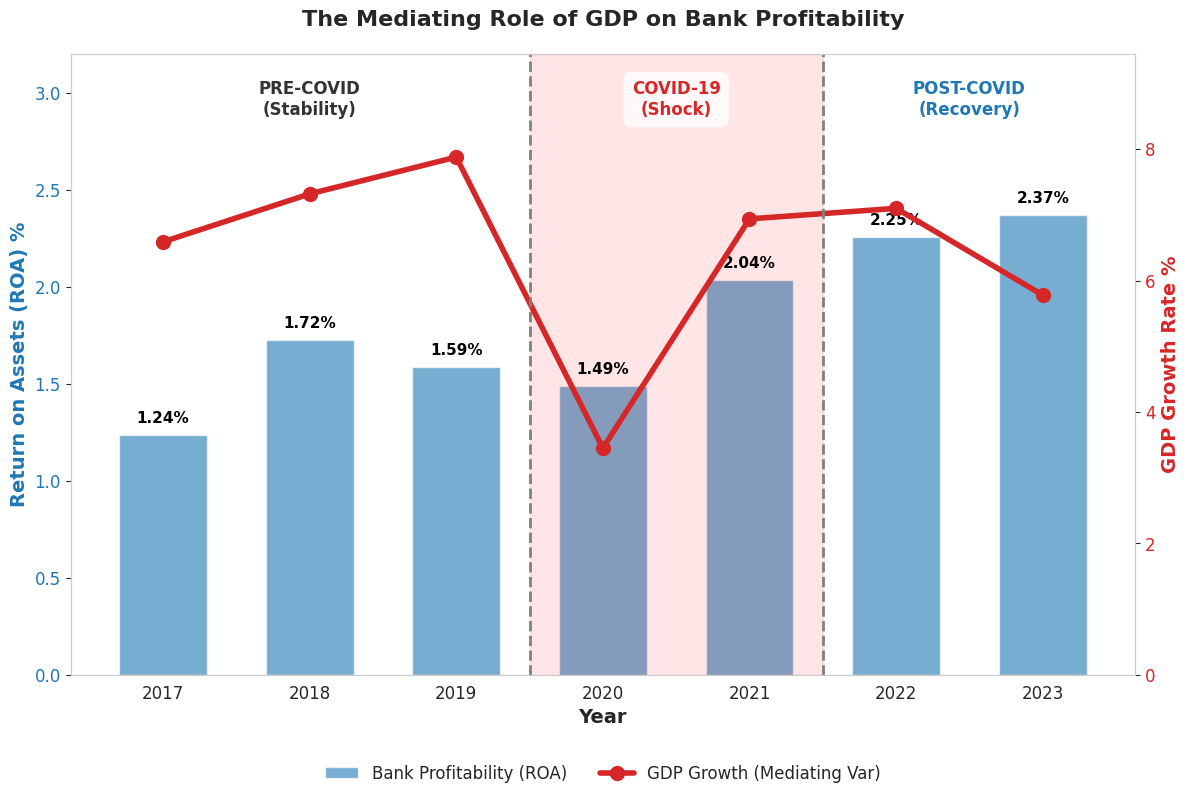

In [55]:
import pandas as pd
import matplotlib.pyplot as plt

# Load Data
df = pd.read_csv("Bank Profitability.csv")

# Group data by Year
yearly_data = df.groupby('Year')[['ROA', 'GDP']].mean().reset_index()

# Setup the Plot (Increased height slightly for bottom legend)
fig, ax1 = plt.subplots(figsize=(12, 8))

# --- PLOT 1: Bank Profitability (ROA) as Bars ---
color_roa = '#1f77b4'
bars = ax1.bar(yearly_data['Year'], yearly_data['ROA'], color=color_roa, alpha=0.6, label='Bank Profitability (ROA)', width=0.6)

# Configure Primary Axis (ROA)
ax1.set_xlabel('Year', fontsize=14, fontweight='bold')
ax1.set_ylabel('Return on Assets (ROA) %', color=color_roa, fontsize=14, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color_roa, labelsize=12)
ax1.tick_params(axis='x', labelsize=12)

# Headroom for text labels
max_roa_height = yearly_data['ROA'].max()
ax1.set_ylim(0, max_roa_height * 1.35)

# Add value labels
for bar in bars:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + (max_roa_height * 0.02),
             f'{height:.2f}%',
             ha='center', va='bottom', fontsize=11, fontweight='bold', color='black')

# --- PLOT 2: Macro Variable (GDP) as Line ---
ax2 = ax1.twinx()
color_gdp = '#d62728'
ax2.plot(yearly_data['Year'], yearly_data['GDP'], color=color_gdp, marker='o', linestyle='-', linewidth=4, markersize=10, label='GDP Growth (Mediating Var)')
ax2.set_ylabel('GDP Growth Rate %', color=color_gdp, fontsize=14, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_gdp, labelsize=12)
ax2.set_ylim(0, yearly_data['GDP'].max() * 1.2)

# --- ZONES ---
text_height = max_roa_height * 1.25

# Zone 1: Pre-COVID
plt.axvline(x=2019.5, color='gray', linestyle='--', linewidth=2)
ax1.text(2018, text_height, 'PRE-COVID\n(Stability)', ha='center', va='center', fontsize=12, fontweight='bold', color='#333',
         bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', boxstyle='round,pad=0.5'))

# Zone 2: COVID
plt.axvline(x=2021.5, color='gray', linestyle='--', linewidth=2)
ax1.text(2020.5, text_height, 'COVID-19\n(Shock)', ha='center', va='center', fontsize=12, fontweight='bold', color='#d62728',
         bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', boxstyle='round,pad=0.5'))
ax1.axvspan(2019.5, 2021.5, color='red', alpha=0.1)

# Zone 3: Post-COVID
ax1.text(2022.5, text_height, 'POST-COVID\n(Recovery)', ha='center', va='center', fontsize=12, fontweight='bold', color='#1f77b4',
         bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', boxstyle='round,pad=0.5'))

# --- Final Formatting ---
plt.title('The Mediating Role of GDP on Bank Profitability', fontsize=16, fontweight='bold', pad=20)
ax1.grid(False)
ax2.grid(False)

# LEGEND MOVED TO BOTTOM
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=12, frameon=False)

plt.tight_layout()
plt.subplots_adjust(bottom=0.15) # Ensure space for the legend
plt.savefig('v_shaped_recovery_legend_fixed.png', dpi=300)
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

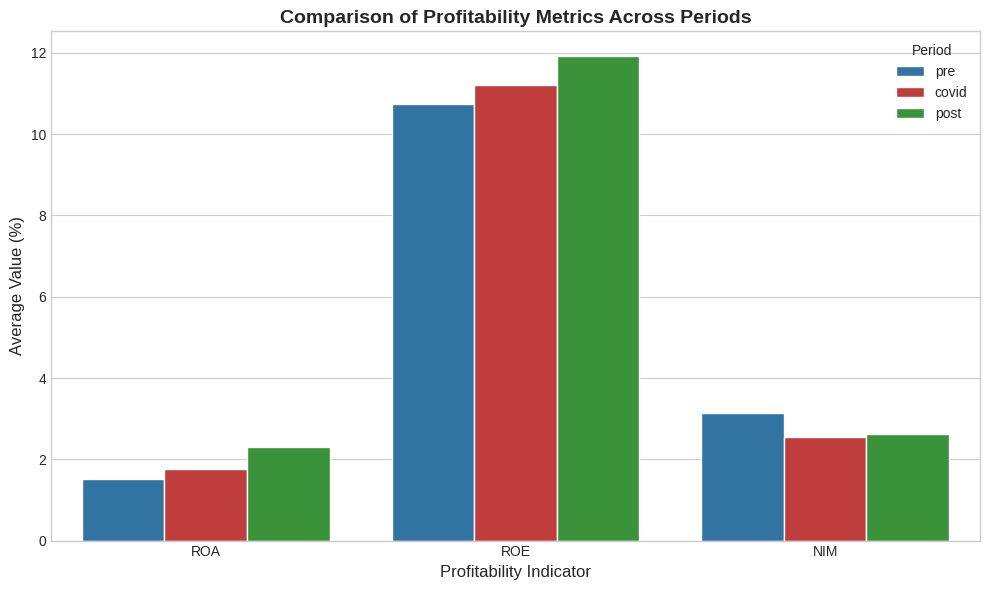

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
df = pd.read_csv("Bank Profitability.csv")

# Aggregate data
profit_period = df.groupby('Period')[['ROA', 'ROE', 'NIM']].mean().reset_index()

# Ensure correct chronological order
period_order = ['pre', 'covid', 'post']
profit_period['Period'] = pd.Categorical(profit_period['Period'], categories=period_order, ordered=True)
profit_period = profit_period.sort_values('Period')

# Transform for plotting
profit_period_melt = profit_period.melt(
    id_vars="Period",
    value_vars=["ROA", "ROE", "NIM"],
    var_name="Metric",
    value_name="Value"
)

# Plotting with custom colors
plt.style.use('seaborn-v0_8-whitegrid')
plt.figure(figsize=(10, 6))

# Define custom palette where 'covid' is red
custom_palette = {'pre': '#1f77b4', 'covid': '#d62728', 'post': '#2ca02c'} # Blue, Red, Green

# Group by Metric on X-axis, Hue by Period
sns.barplot(
    data=profit_period_melt,
    x="Metric",
    y="Value",
    hue="Period",
    palette=custom_palette
)

plt.title("Comparison of Profitability Metrics Across Periods", fontsize=14, fontweight='bold')
plt.ylabel("Average Value (%)", fontsize=12)
plt.xlabel("Profitability Indicator", fontsize=12)
plt.legend(title='Period')

plt.tight_layout()
plt.savefig('profitability_metric_grouped_red_covid.png', dpi=300)
plt.show()

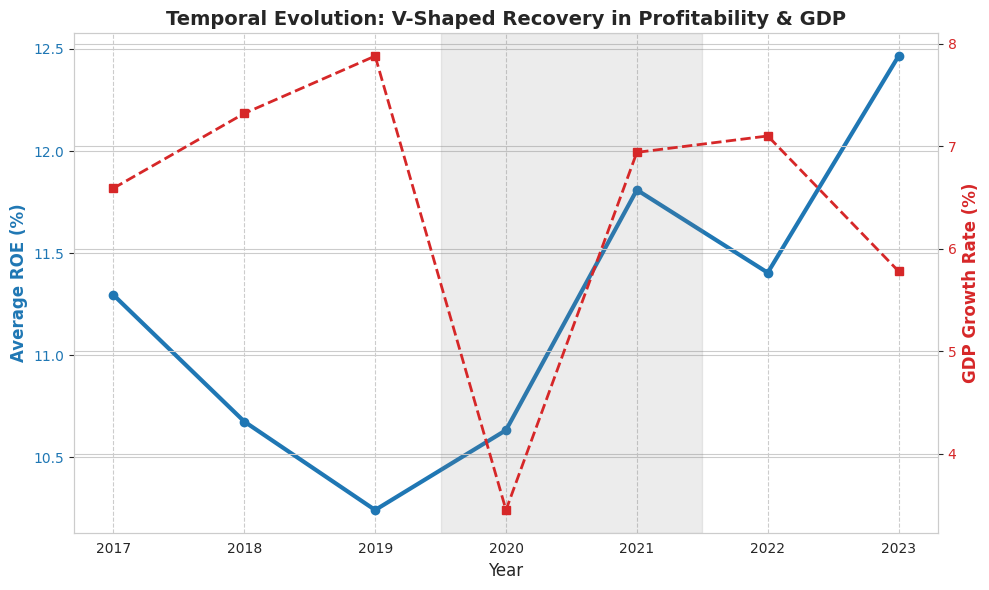

In [44]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Bank Profitability.csv")
annual_avg = df.groupby('Year')[['ROE', 'GDP']].mean().reset_index()

fig, ax1 = plt.subplots(figsize=(10, 6))

# Primary Axis: ROE
color_roe = '#1f77b4'  # Blue
ax1.set_xlabel('Year', fontsize=12)
ax1.set_ylabel('Average ROE (%)', color=color_roe, fontsize=12, fontweight='bold')
ax1.plot(annual_avg['Year'], annual_avg['ROE'], color=color_roe, marker='o', linewidth=3, label='Bank ROE')
ax1.tick_params(axis='y', labelcolor=color_roe)
ax1.grid(visible=True, which='major', axis='x', linestyle='--')

# Secondary Axis: GDP
ax2 = ax1.twinx()
color_gdp = '#d62728'  # Red
ax2.set_ylabel('GDP Growth Rate (%)', color=color_gdp, fontsize=12, fontweight='bold')
ax2.plot(annual_avg['Year'], annual_avg['GDP'], color=color_gdp, linestyle='--', marker='s', linewidth=2, label='GDP Growth')
ax2.tick_params(axis='y', labelcolor=color_gdp)

# Highlight COVID Period
plt.axvspan(2019.5, 2021.5, color='gray', alpha=0.15, label='COVID-19 Shock')

plt.title('Temporal Evolution: V-Shaped Recovery in Profitability & GDP', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('Chart1_VShape.png', dpi=300)
plt.show()

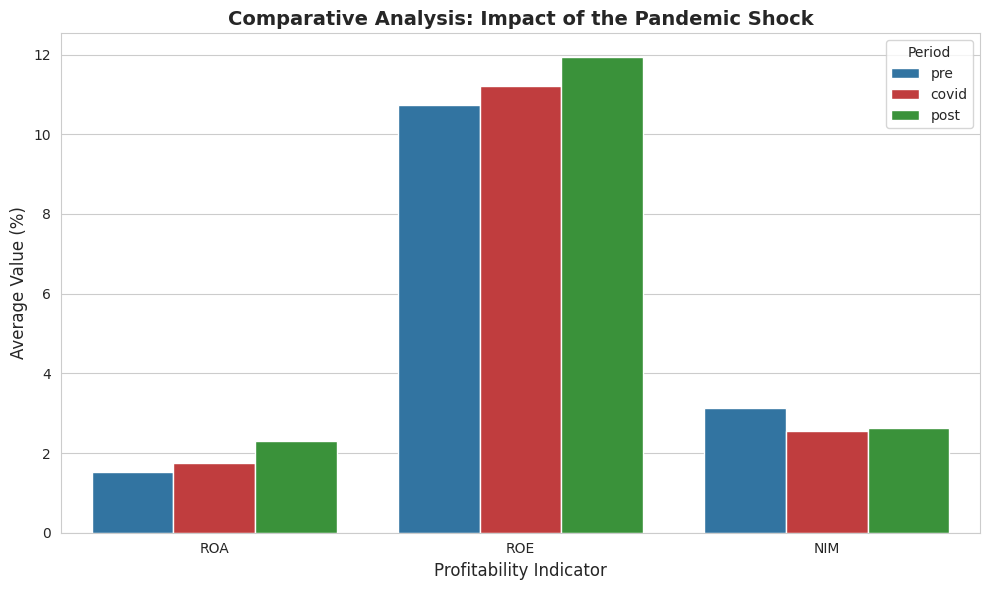

In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Bank Profitability.csv")

# Aggregate and Order
profit_period = df.groupby('Period')[['ROA', 'ROE', 'NIM']].mean().reset_index()
period_order = ['pre', 'covid', 'post']
profit_period['Period'] = pd.Categorical(profit_period['Period'], categories=period_order, ordered=True)
profit_period = profit_period.sort_values('Period')

# Melt for grouping
profit_melt = profit_period.melt(id_vars="Period", value_vars=["ROA", "ROE", "NIM"], var_name="Metric", value_name="Value")

# Plot
plt.figure(figsize=(10, 6))
# Colors: Blue (Pre), Red (Covid), Green (Post)
custom_palette = {'pre': '#1f77b4', 'covid': '#d62728', 'post': '#2ca02c'}

sns.barplot(data=profit_melt, x="Metric", y="Value", hue="Period", palette=custom_palette)

plt.title("Comparative Analysis: Impact of the Pandemic Shock", fontsize=14, fontweight='bold')
plt.ylabel("Average Value (%)", fontsize=12)
plt.xlabel("Profitability Indicator", fontsize=12)
plt.legend(title='Period')
plt.tight_layout()
plt.savefig('Chart2_BarComparison.png', dpi=300)
plt.show()

<Figure size 1000x600 with 0 Axes>

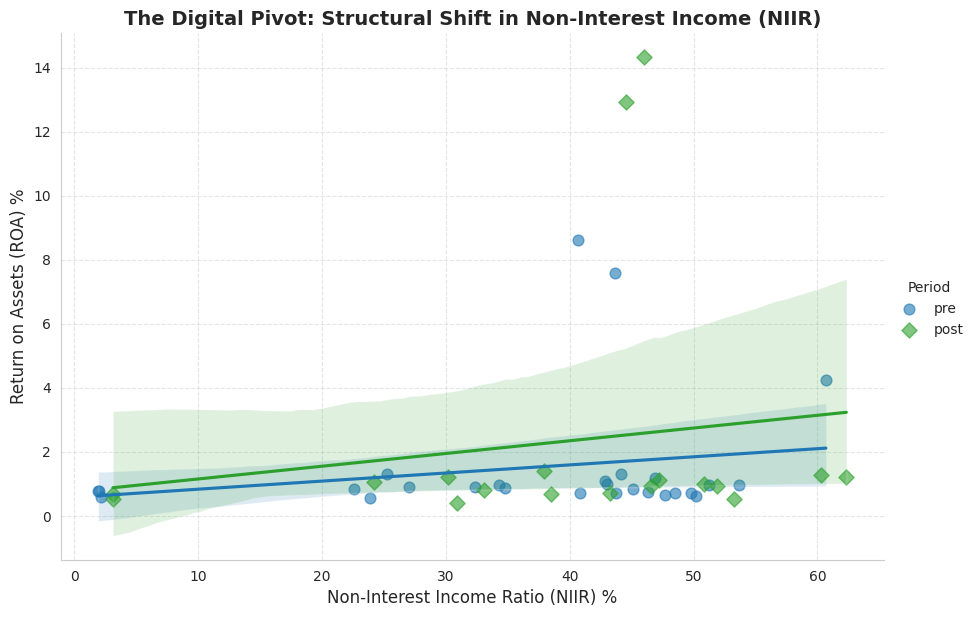

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

# Plot with regression lines for Pre vs Post
sns.lmplot(data=df[df['Period'] != 'covid'], x='NIIR', y='ROA', hue='Period',
           height=6, aspect=1.5, palette={'pre': '#1f77b4', 'post': '#2ca02c'},
           markers=['o', 'D'], scatter_kws={'s': 60, 'alpha': 0.6})

plt.title('The Digital Pivot: Structural Shift in Non-Interest Income (NIIR)', fontsize=14, fontweight='bold')
plt.xlabel('Non-Interest Income Ratio (NIIR) %', fontsize=12)
plt.ylabel('Return on Assets (ROA) %', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig('Chart3_DigitalShift.png', dpi=300)
plt.show()

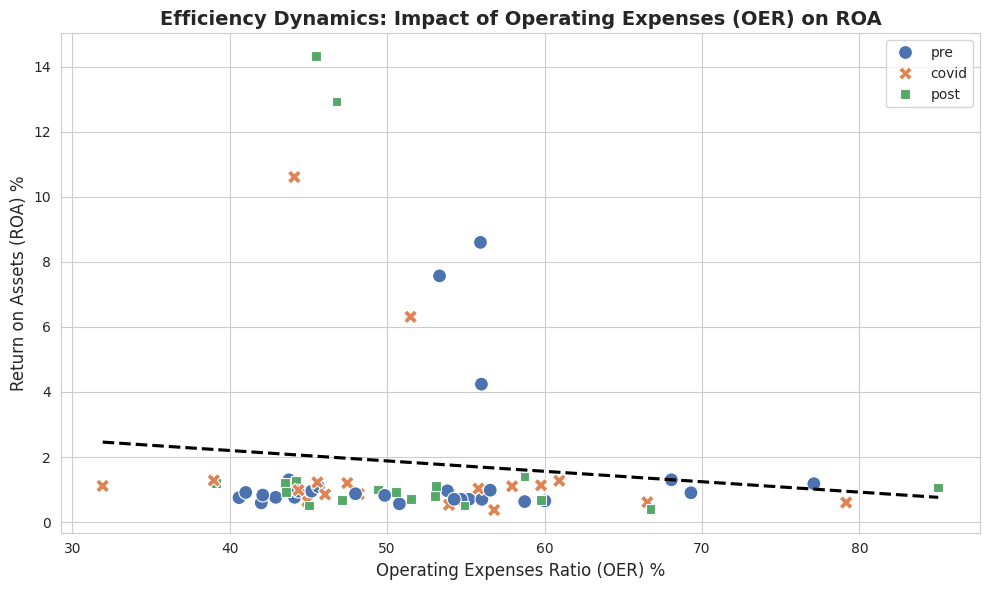

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

# Scatter plot of OER vs ROA
sns.scatterplot(data=df, x='OER', y='ROA', hue='Period', style='Period', s=100, palette='deep')

# Add a single trendline to show the general negative correlation
sns.regplot(data=df, x='OER', y='ROA', scatter=False, color='black', ci=None, line_kws={'linestyle':'--'})

plt.title('Efficiency Dynamics: Impact of Operating Expenses (OER) on ROA', fontsize=14, fontweight='bold')
plt.xlabel('Operating Expenses Ratio (OER) %', fontsize=12)
plt.ylabel('Return on Assets (ROA) %', fontsize=12)
plt.legend()
plt.tight_layout()
plt.savefig('Chart4_Efficiency.png', dpi=300)
plt.show()

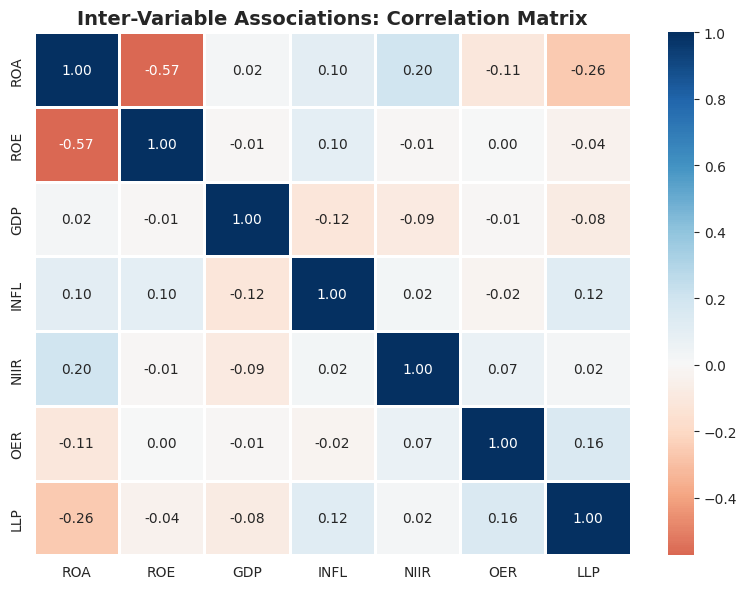

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
corr_cols = ['ROA', 'ROE', 'GDP', 'INFL', 'NIIR', 'OER', 'LLP']
corr_matrix = df[corr_cols].corr()

sns.heatmap(corr_matrix, annot=True, cmap='RdBu', center=0, fmt=".2f", linewidths=1, linecolor='white')

plt.title('Inter-Variable Associations: Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('Chart5_Correlation.png', dpi=300)
plt.show()

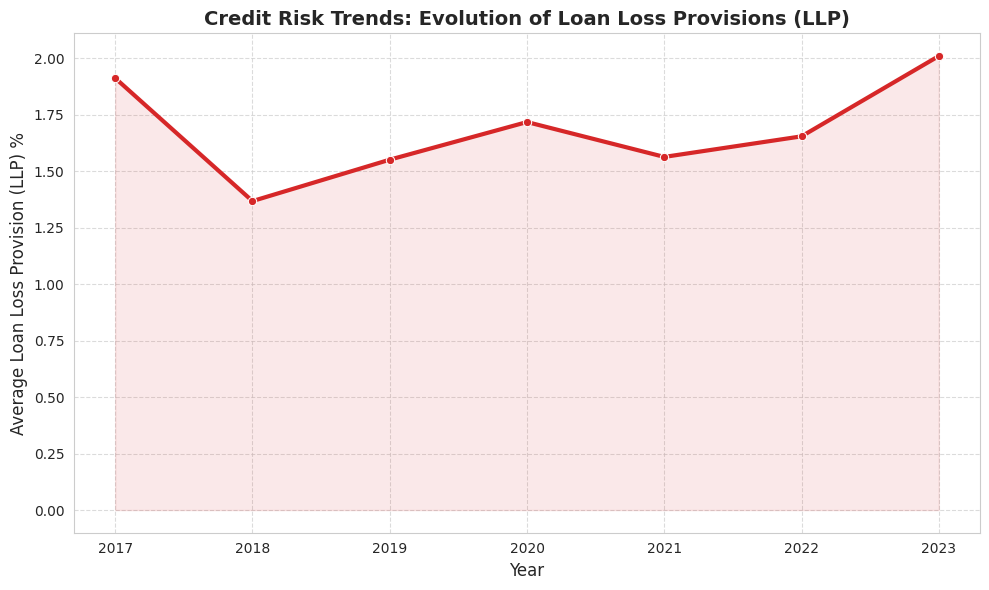

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns

llp_trend = df.groupby('Year')['LLP'].mean().reset_index()

plt.figure(figsize=(10, 6))
sns.lineplot(data=llp_trend, x='Year', y='LLP', marker='o', linewidth=3, color='#d62728')
plt.fill_between(llp_trend['Year'], llp_trend['LLP'], alpha=0.1, color='#d62728')

plt.title('Credit Risk Trends: Evolution of Loan Loss Provisions (LLP)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Average Loan Loss Provision (LLP) %', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('Chart6_RiskLLP.png', dpi=300)
plt.show()

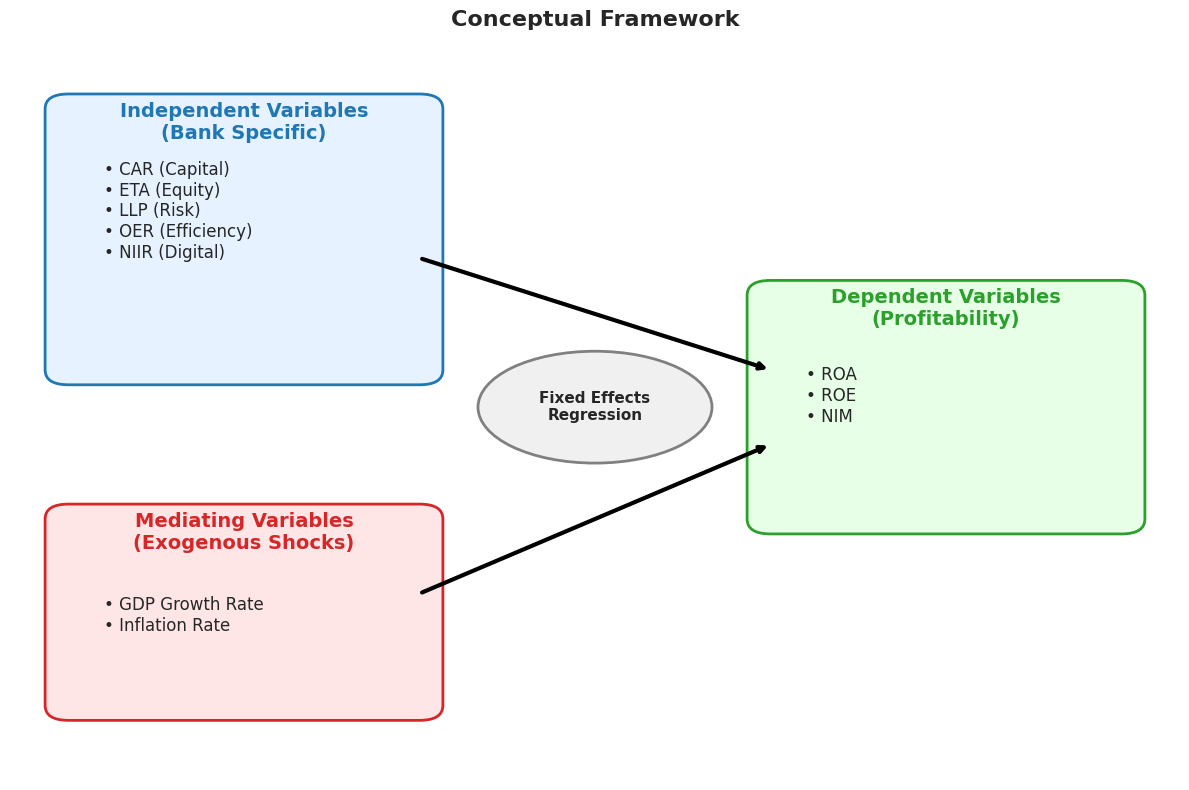

In [52]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def draw_conceptual_framework():
    fig, ax = plt.subplots(figsize=(12, 8))
    ax.axis('off')

    # Styles
    title_style = dict(fontsize=14, fontweight='bold', ha='center')
    text_style = dict(fontsize=12, ha='left')

    # 1. Independent Variables (Top Left)
    ax.add_patch(patches.FancyBboxPatch((0.05, 0.55), 0.3, 0.35, boxstyle="round,pad=0.02", ec='#1f77b4', fc='#e6f2ff', lw=2))
    ax.text(0.2, 0.86, "Independent Variables\n(Bank Specific)", **title_style, color='#1f77b4')
    ax.text(0.08, 0.70, "• CAR (Capital)\n• ETA (Equity)\n• LLP (Risk)\n• OER (Efficiency)\n• NIIR (Digital)", **text_style)

    # 2. Mediating Variables (Bottom Left)
    ax.add_patch(patches.FancyBboxPatch((0.05, 0.1), 0.3, 0.25, boxstyle="round,pad=0.02", ec='#d62728', fc='#ffe6e6', lw=2))
    ax.text(0.2, 0.31, "Mediating Variables\n(Exogenous Shocks)", **title_style, color='#d62728')
    ax.text(0.08, 0.20, "• GDP Growth Rate\n• Inflation Rate", **text_style)

    # 3. Dependent Variables (Right)
    ax.add_patch(patches.FancyBboxPatch((0.65, 0.35), 0.3, 0.3, boxstyle="round,pad=0.02", ec='#2ca02c', fc='#e6ffe6', lw=2))
    ax.text(0.8, 0.61, "Dependent Variables\n(Profitability)", **title_style, color='#2ca02c')
    ax.text(0.68, 0.48, "• ROA\n• ROE\n• NIM", **text_style)

    # Arrows & Method Center
    ax.annotate("", xy=(0.65, 0.55), xytext=(0.35, 0.7), arrowprops=dict(arrowstyle="->", lw=3, color='black'))
    ax.annotate("", xy=(0.65, 0.45), xytext=(0.35, 0.25), arrowprops=dict(arrowstyle="->", lw=3, color='black'))

    # Method Bubble
    ax.add_patch(patches.Ellipse((0.5, 0.5), 0.2, 0.15, ec='gray', fc='#f0f0f0', lw=2))
    ax.text(0.5, 0.5, "Fixed Effects\nRegression", fontsize=11, fontweight='bold', ha='center', va='center')

    plt.title("Conceptual Framework", fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.savefig('Chart7_Framework.png', dpi=300)
    plt.show()

draw_conceptual_framework()